# 08 — Support Vector Machines & Kernel Methods
### From Constrained Optimization to Maximum-Margin Classifiers and the Kernel Trick

---

> **Position in the series:**
> `01_statistical_learning_theory` → `02_pac_and_vc_dimensions` → `03_linear_algebra_and_geometry` → `04_pca` → `05_gaussian_mixture_models` → `06_linear_regression` → `07_logistic_regression` → **`08_svm_and_kernel_methods`**

---

## References

| # | Source |
|---|--------|
| [1] | Andrew Ng (updated by Tengyu Ma) — *CS229 Lecture Notes*, Part V (Kernel Methods) and Part VI (Support Vector Machines), Stanford (2019) |
| [2] | Iacopo Masi — SVM & kernel lecture slides, Sapienza SMIA |
| [3] | C. M. Bishop — *Pattern Recognition and Machine Learning*, Springer, 2006 — Ch. 6 (Kernel Methods), Ch. 7.1 (Maximum Margin Classifiers), Appendix E (Lagrange Multipliers) |
| [4] | M. P. Deisenroth, A. A. Faisal & C. S. Ong — *Mathematics for Machine Learning*, Cambridge, 2020 — Ch. 7.2 (Constrained Optimization & Lagrange Multipliers), Ch. 12 (Classification with SVMs) |
| [5] | S. Shalev-Shwartz & S. Ben-David — *Understanding Machine Learning*, Cambridge, 2014 — Ch. 6 (VC Dimension), Ch. 15 (SVM), Ch. 16 (Kernel Methods) |
| [6] | T. Hastie, R. Tibshirani & J. Friedman — *The Elements of Statistical Learning*, 2nd ed., Springer, 2009 — Ch. 12 |
| [7] | V. N. Vapnik — *The Nature of Statistical Learning Theory*, Springer, 1995 *(margin-based VC bound)* |
| [8] | S. Boyd & L. Vandenberghe — *Convex Optimization*, Cambridge, 2004 — Ch. 5 (Duality, KKT) |

---

## Structure

**Part I — Constrained Optimization**
1. Lagrange Multipliers for Equality Constraints
2. Inequality Constraints: Active vs. Inactive
3. The Lagrangian, Primal and Dual — Weak & Strong Duality
4. The Karush–Kuhn–Tucker (KKT) Conditions

**Part II — Hyperplanes & Margin**
5. Hyperplanes, Signed Distance and the $\pm1$ Label Convention
6. Functional vs. Geometric Margin

**Part III — Support Vector Machines**
7. The Hard-Margin SVM: Primal Problem
8. The Lagrangian Dual of the SVM
9. Implementation Remark: $\alpha_i>0 \iff$ Support Vector
10. Soft-Margin SVM: Slack Variables and the Box Constraint
11. The Role of $C$

**Part IV — Remark: VC Dimension and the Margin**
12. Shattering by Hyperplanes (recap of `02`)
13. The Margin Bound: Capacity Without Dimension

**Part V — Kernel Methods**
14. Feature Maps: When Linear Is Not Enough
15. The Kernel Trick
16. Valid Kernels: Mercer's Theorem and the Gram Matrix
17. The Gaussian (RBF) Kernel: An Infinite-Dimensional Feature Map
18. Kernel SVM End-to-End

---
## 0. Preview — The Model in One Page

Before the machinery, here is where we are going.

**The question.** For linearly separable data there are *infinitely many* separating hyperplanes $\mathbf{w}^T\mathbf{x}+b=0$. Logistic regression (`07`) picks one through the likelihood. The SVM picks the one that **maximizes the margin** — the distance to the closest training points of either class.

**The optimization problem.** With labels $y_i\in\{-1,+1\}$:

$$\min_{\mathbf{w},b}\ \tfrac12\|\mathbf{w}\|^2 \quad\text{s.t.}\quad y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge 1,\quad i=1,\dots,N$$

This is a **constrained** problem: that is why Part I builds the Lagrangian and the KKT conditions first.

**The key consequence.** Introducing one multiplier $\alpha_i\ge0$ per constraint, the KKT *complementary slackness* condition reads

$$\alpha_i\big[y_i(\mathbf{w}^T\mathbf{x}_i+b)-1\big]=0,$$

so either $\alpha_i=0$ (the point is irrelevant) or the point sits **exactly on the margin** ($\alpha_i>0$, a **support vector**). The solution $\mathbf{w}=\sum_i\alpha_iy_i\mathbf{x}_i$ depends only on these few points.

**Why it generalizes.** Large margin $\Rightarrow$ small effective VC dimension, *independently* of the ambient dimension (Part IV).

**Why it scales to nonlinear problems.** The dual problem touches the data only through inner products $\mathbf{x}_i^T\mathbf{x}_j$. Replacing them with a kernel $K(\mathbf{x}_i,\mathbf{x}_j)=\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)$ gives a linear classifier in a (possibly infinite-dimensional) feature space without ever computing $\phi$ (Part V).

---
# Part I — Constrained Optimization

---
## 1. Lagrange Multipliers for Equality Constraints

Every model so far (`06`, `07`) was trained by **unconstrained** minimization: set $\nabla J=\mathbf{0}$ or follow $-\nabla J$. The SVM will require minimizing a function *subject to constraints*. Start from the simplest case:

$$\min_{\mathbf{x}} f(\mathbf{x}) \quad\text{s.t.}\quad h(\mathbf{x})=0$$

### Geometric Argument

Move along the constraint surface $h(\mathbf{x})=0$. At a constrained optimum $\mathbf{x}^\star$, any feasible infinitesimal move $\mathbf{d}$ is tangent to the surface ($\nabla h^T\mathbf{d}=0$) and must not decrease $f$ to first order ($\nabla f^T\mathbf{d}=0$). So $\nabla f$ must be orthogonal to every tangent direction — i.e. **parallel to $\nabla h$**:

$$\boxed{\nabla f(\mathbf{x}^\star) + \beta\,\nabla h(\mathbf{x}^\star) = \mathbf{0}} \quad\text{for some }\beta\in\mathbb{R}$$

If $\nabla f$ had a component along the tangent, sliding in the opposite direction along the constraint would lower $f$ while staying feasible.

### The Lagrangian

Define $\mathcal{L}(\mathbf{x},\beta) = f(\mathbf{x}) + \beta\,h(\mathbf{x})$. Then

$$\nabla_\mathbf{x}\mathcal{L}=\mathbf{0} \;\Longleftrightarrow\; \nabla f = -\beta\nabla h, \qquad \frac{\partial\mathcal{L}}{\partial\beta}=0 \;\Longleftrightarrow\; h(\mathbf{x})=0$$

The **constrained** problem in $\mathbf{x}$ becomes an **unconstrained** stationarity problem in $(\mathbf{x},\beta)$.

**Example:** $f(\mathbf{x})=x_1+x_2$ on the circle $h(\mathbf{x})=x_1^2+x_2^2-2=0$. Stationarity: $1+2\beta x_1=0$, $1+2\beta x_2=0 \Rightarrow x_1=x_2=-\tfrac{1}{2\beta}$; substituting into $h$ gives $\beta=\pm\tfrac12$. The minimum is $\mathbf{x}^\star=(-1,-1)$ with $\beta=\tfrac12$.

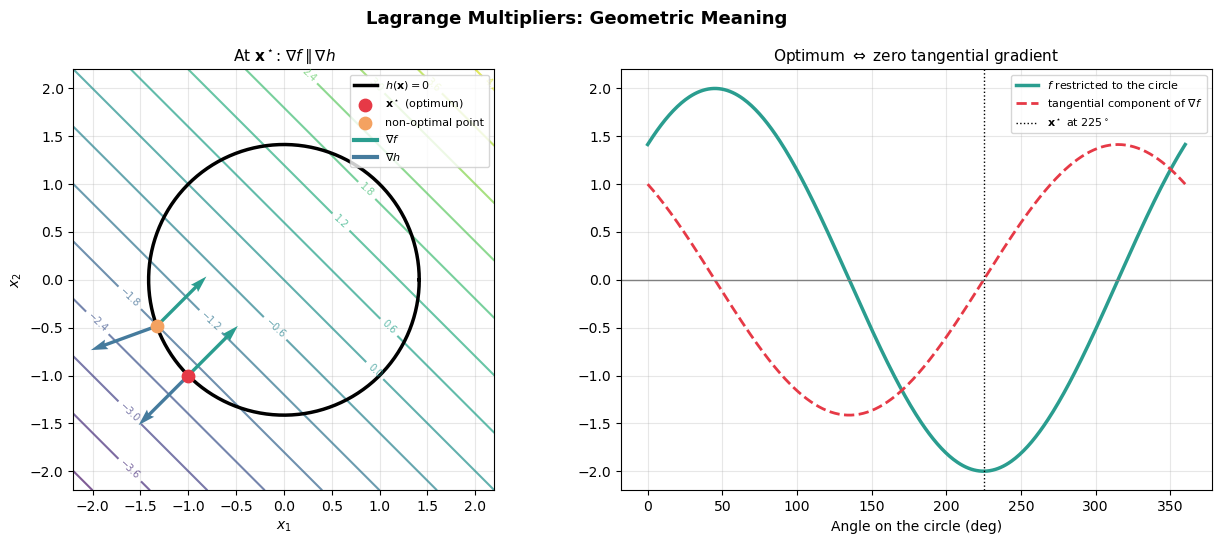

beta = 0.500   residual of grad f + beta grad h = [0. 0.]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# f(x) = x1 + x2  subject to  h(x) = x1^2 + x2^2 - 2 = 0
f      = lambda x1, x2: x1 + x2
grad_f = lambda x: np.array([1.0, 1.0])
grad_h = lambda x: 2 * x

xx, yy = np.meshgrid(np.linspace(-2.2, 2.2, 300), np.linspace(-2.2, 2.2, 300))
theta  = np.linspace(0, 2*np.pi, 400)
r      = np.sqrt(2)

x_star = np.array([-1.0, -1.0])                         # analytic minimum
x_bad  = np.array([r*np.cos(np.deg2rad(200)), r*np.sin(np.deg2rad(200))])   # feasible, not optimal

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
cs = ax.contour(xx, yy, f(xx, yy), levels=15, cmap='viridis', alpha=0.7)
ax.clabel(cs, fontsize=7)
ax.plot(r*np.cos(theta), r*np.sin(theta), 'k', lw=2.5, label=r'$h(\mathbf{x})=0$')
for p, col, name in [(x_star, '#E63946', r'$\mathbf{x}^\star$ (optimum)'), (x_bad, '#F4A261', 'non-optimal point')]:
    gf, gh = grad_f(p), grad_h(p)
    ax.scatter(*p, s=80, color=col, zorder=6, label=name)
    ax.quiver(*p, *(gf/np.linalg.norm(gf)), color='#2A9D8F', scale=6, width=0.008, zorder=5)
    ax.quiver(*p, *(gh/np.linalg.norm(gh)), color='#457B9D', scale=6, width=0.008, zorder=5)
ax.plot([], [], color='#2A9D8F', lw=3, label=r'$\nabla f$')
ax.plot([], [], color='#457B9D', lw=3, label=r'$\nabla h$')
ax.set_aspect('equal'); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title(r'At $\mathbf{x}^\star$: $\nabla f \parallel \nabla h$', fontsize=11)
ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)

# Right: f along the circle, and the tangential component of grad f
ang   = np.linspace(0, 2*np.pi, 400)
pts   = np.column_stack([r*np.cos(ang), r*np.sin(ang)])
tang  = np.column_stack([-np.sin(ang), np.cos(ang)])            # unit tangent to the circle
f_on  = pts.sum(axis=1)
g_tan = tang @ np.array([1.0, 1.0])                             # grad f projected on the tangent

ax = axes[1]
ax.plot(np.rad2deg(ang), f_on, '#2A9D8F', lw=2.5, label=r'$f$ restricted to the circle')
ax.plot(np.rad2deg(ang), g_tan, '#E63946', lw=2, linestyle='--', label=r'tangential component of $\nabla f$')
ax.axhline(0, color='gray', lw=1)
ax.axvline(225, color='k', lw=1, linestyle=':', label=r'$\mathbf{x}^\star$ at $225^\circ$')
ax.set_xlabel('Angle on the circle (deg)'); ax.set_title('Optimum $\\Leftrightarrow$ zero tangential gradient', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('Lagrange Multipliers: Geometric Meaning', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

beta = -grad_f(x_star)[0] / grad_h(x_star)[0]
print(f"beta = {beta:.3f}   residual of grad f + beta grad h = {grad_f(x_star) + beta*grad_h(x_star)}")

---
## 2. Inequality Constraints: Active vs. Inactive

The SVM constraints are **inequalities**. Consider

$$\min_{\mathbf{x}} f(\mathbf{x}) \quad\text{s.t.}\quad g(\mathbf{x})\le 0$$

Only two things can happen at the optimum:

| Case | Where is $\mathbf{x}^\star$? | Condition | Multiplier |
|------|------------------------------|-----------|------------|
| **Inactive** constraint | strictly inside, $g(\mathbf{x}^\star)<0$ | the constraint plays no role: $\nabla f(\mathbf{x}^\star)=\mathbf{0}$ | $\alpha=0$ |
| **Active** constraint | on the boundary, $g(\mathbf{x}^\star)=0$ | as in Section 1: $\nabla f=-\alpha\nabla g$ | $\alpha>0$ |

In the active case the **sign** of $\alpha$ matters. $\nabla g$ points *out of* the feasible region (towards increasing $g$). At the optimum $f$ must not decrease when moving inward, so $-\nabla f$ must point **outward**, i.e. along $+\nabla g$:

$$-\nabla f(\mathbf{x}^\star) = \alpha\,\nabla g(\mathbf{x}^\star), \qquad \alpha\ge0$$

Both cases are summarized by a single product:

$$\boxed{\alpha\, g(\mathbf{x}^\star) = 0}$$

either the multiplier is zero, or the constraint is tight. This is **complementary slackness**, and it is the exact mechanism that will select the support vectors in Section 9.

**Example:** $f(\mathbf{x})=\|\mathbf{x}-\mathbf{c}\|^2$ (distance to a target $\mathbf{c}$) restricted to the unit disk $g(\mathbf{x})=\|\mathbf{x}\|^2-1\le0$.
* $\mathbf{c}$ outside the disk $\Rightarrow$ $\mathbf{x}^\star=\mathbf{c}/\|\mathbf{c}\|$, and stationarity $2(\mathbf{x}^\star-\mathbf{c})+2\alpha\mathbf{x}^\star=\mathbf{0}$ gives $\alpha=\|\mathbf{c}\|-1>0$.
* $\mathbf{c}$ inside the disk $\Rightarrow$ $\mathbf{x}^\star=\mathbf{c}$, $\alpha=0$.

Target outside: constraint ACTIVE      x* = [0.8321 0.5547],  alpha = 1.1633  (analytic: 1.1633)
Target inside: constraint INACTIVE     x* = [ 0.35 -0.2 ],  alpha = 0.0000  (analytic: 0.0000)


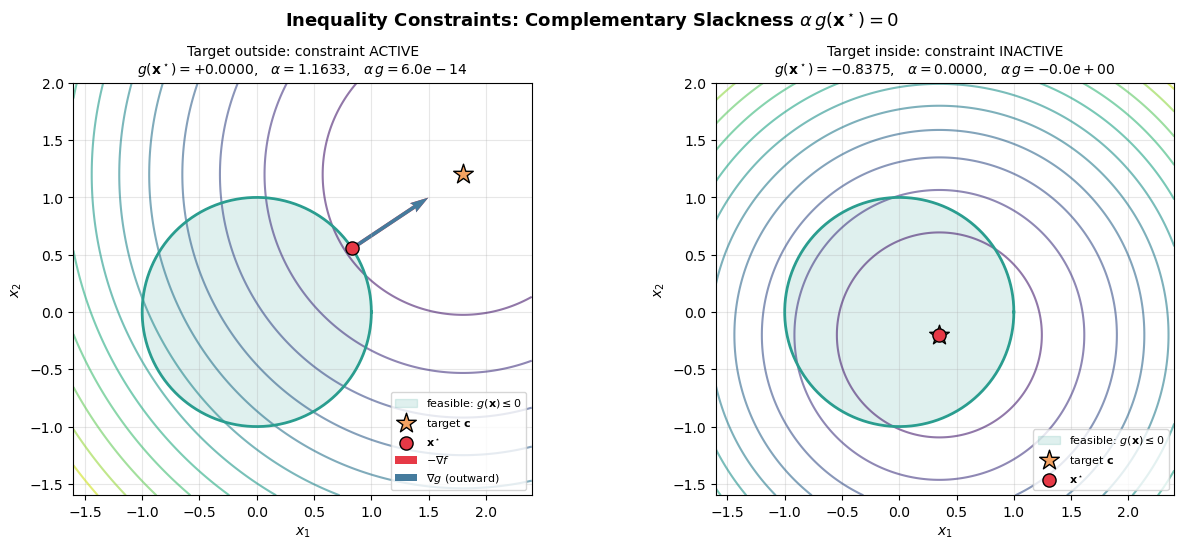

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def solve_disk(c):
    # Numerically solve min ||x-c||^2 s.t. ||x||^2 <= 1 (scipy uses c(x) >= 0 convention)
    res = minimize(lambda x: np.sum((x - c)**2), x0=np.zeros(2),
                   jac=lambda x: 2*(x - c),
                   constraints=[{'type': 'ineq', 'fun': lambda x: 1 - x @ x, 'jac': lambda x: -2*x}],
                   method='SLSQP', options={'ftol': 1e-12})
    x = res.x
    g = x @ x - 1
    # Recover alpha from stationarity: 2(x-c) + alpha * 2x = 0  (least-squares, valid in both cases)
    gf, gg = 2*(x - c), 2*x
    alpha = max(0.0, -(gg @ gf) / (gg @ gg))
    return x, g, alpha

cases = [(np.array([1.8, 1.2]), 'Target outside: constraint ACTIVE'),
         (np.array([0.35, -0.2]), 'Target inside: constraint INACTIVE')]

xx, yy = np.meshgrid(np.linspace(-1.6, 2.4, 300), np.linspace(-1.6, 2.0, 300))
theta  = np.linspace(0, 2*np.pi, 400)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (c, title) in zip(axes, cases):
    x, g, alpha = solve_disk(c)
    ax.contour(xx, yy, (xx - c[0])**2 + (yy - c[1])**2, levels=14, cmap='viridis', alpha=0.6)
    ax.fill(np.cos(theta), np.sin(theta), color='#2A9D8F', alpha=0.15, label=r'feasible: $g(\mathbf{x})\leq 0$')
    ax.plot(np.cos(theta), np.sin(theta), color='#2A9D8F', lw=2)
    ax.scatter(*c, marker='*', s=220, color='#F4A261', edgecolor='k', zorder=6, label=r'target $\mathbf{c}$')
    ax.scatter(*x, s=90, color='#E63946', edgecolor='k', zorder=7, label=r'$\mathbf{x}^\star$')
    if alpha > 1e-8:
        n = x / np.linalg.norm(x)
        ax.quiver(*x, *(-2*(x - c)/np.linalg.norm(2*(x - c))), color='#E63946', scale=5, width=0.008, label=r'$-\nabla f$')
        ax.quiver(*x, *n, color='#457B9D', scale=5, width=0.008, label=r'$\nabla g$ (outward)')
    ax.set_title(f'{title}\n' + rf'$g(\mathbf{{x}}^\star)={g:+.4f}$,   $\alpha={alpha:.4f}$,   $\alpha\,g={alpha*g:.1e}$', fontsize=10)
    ax.set_aspect('equal'); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.legend(fontsize=8, loc='lower right'); ax.grid(True, alpha=0.3)
    print(f"{title:38s} x* = {np.round(x, 4)},  alpha = {alpha:.4f}  (analytic: {max(0, np.linalg.norm(c) - 1):.4f})")

plt.suptitle('Inequality Constraints: Complementary Slackness $\\alpha\\,g(\\mathbf{x}^\\star)=0$', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 3. The Lagrangian, Primal and Dual — Weak & Strong Duality

### General Problem

$$\min_{\mathbf{x}} f(\mathbf{x}) \quad\text{s.t.}\quad g_i(\mathbf{x})\le0\ \ (i=1..m), \qquad h_j(\mathbf{x})=0\ \ (j=1..p)$$

**Generalized Lagrangian** (one multiplier per constraint):

$$\mathcal{L}(\mathbf{x},\boldsymbol\alpha,\boldsymbol\beta) = f(\mathbf{x}) + \sum_{i=1}^m\alpha_i g_i(\mathbf{x}) + \sum_{j=1}^p\beta_j h_j(\mathbf{x}), \qquad \alpha_i\ge0$$

### The Primal as a Min–Max

Define $\theta_P(\mathbf{x}) = \max_{\boldsymbol\alpha\ge0,\boldsymbol\beta}\mathcal{L}(\mathbf{x},\boldsymbol\alpha,\boldsymbol\beta)$. If $\mathbf{x}$ violates any constraint ($g_i>0$ or $h_j\neq0$), the adversary sends the corresponding multiplier to $\pm\infty$; otherwise the best it can do is $\alpha_ig_i=0$:

$$\theta_P(\mathbf{x}) = \begin{cases} f(\mathbf{x}) & \mathbf{x}\text{ feasible}\\ +\infty & \text{otherwise}\end{cases}
\qquad\Longrightarrow\qquad
\boxed{p^\star = \min_\mathbf{x}\ \max_{\boldsymbol\alpha\ge0,\boldsymbol\beta}\mathcal{L}}$$

The constraints are now hidden inside an **unconstrained** min–max.

### The Dual: Swap the Order

$$\theta_D(\boldsymbol\alpha,\boldsymbol\beta)=\min_\mathbf{x}\mathcal{L}(\mathbf{x},\boldsymbol\alpha,\boldsymbol\beta), \qquad \boxed{d^\star=\max_{\boldsymbol\alpha\ge0,\boldsymbol\beta}\ \min_\mathbf{x}\mathcal{L}}$$

$\theta_D$ is a pointwise minimum of functions affine in $(\boldsymbol\alpha,\boldsymbol\beta)$, so it is **always concave** — even when the primal is not convex.

### Weak Duality (always)

For any feasible $\tilde{\mathbf{x}}$ and any $\boldsymbol\alpha\ge0$: $\theta_D(\boldsymbol\alpha,\boldsymbol\beta)\le\mathcal{L}(\tilde{\mathbf{x}},\boldsymbol\alpha,\boldsymbol\beta)\le f(\tilde{\mathbf{x}})$, since $\alpha_ig_i(\tilde{\mathbf{x}})\le0$ and $h_j(\tilde{\mathbf{x}})=0$. Hence

$$d^\star \le p^\star \qquad(\text{the gap } p^\star-d^\star\ge0 \text{ is the duality gap})$$

### Strong Duality (under conditions)

If $f$ and all $g_i$ are **convex**, all $h_j$ are **affine**, and **Slater's condition** holds (there exists a strictly feasible point, $g_i(\mathbf{x})<0\ \forall i$; for affine $g_i$ plain feasibility is enough), then

$$\boxed{d^\star = p^\star}$$

and we may solve whichever of the two problems is easier. **This is exactly the situation of the SVM** (convex quadratic objective, affine constraints).

**Example:** $\min_x x^2$ s.t. $1-x\le0$. Then $\mathcal{L}=x^2+\alpha(1-x)$, $\min_x$ gives $x=\alpha/2$, so $\theta_D(\alpha)=\alpha-\alpha^2/4$, maximized at $\alpha^\star=2$: $d^\star=1=p^\star$ (attained at $x^\star=1$).

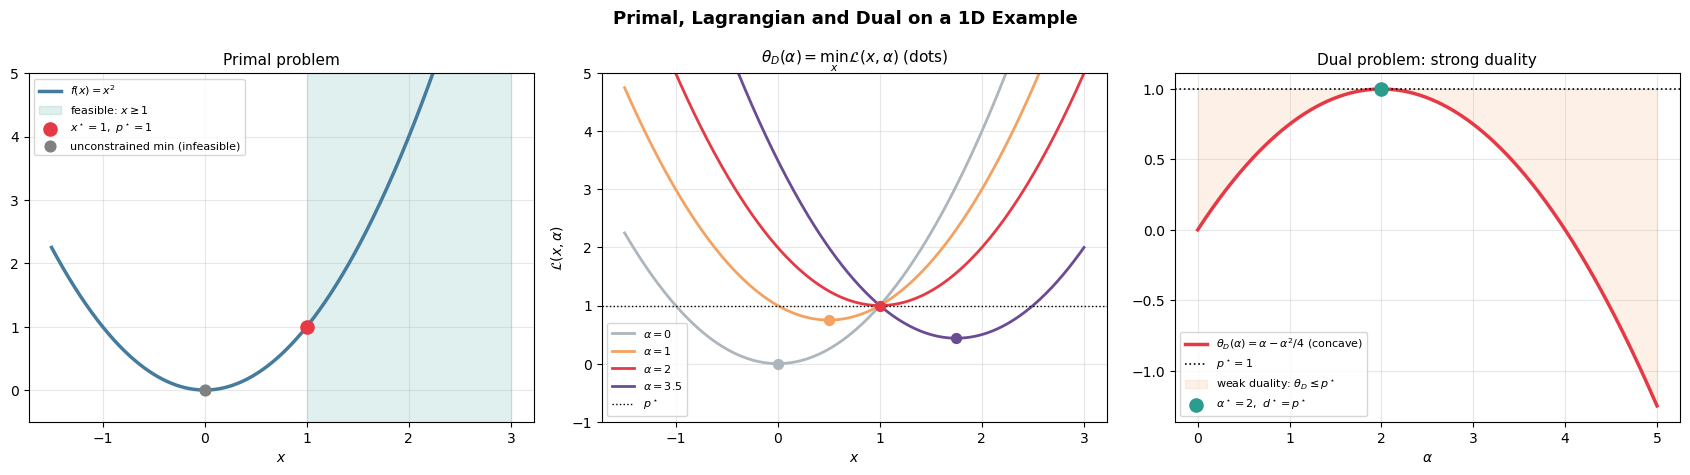

d* = max theta_D = 1.0000 at alpha = 2.005;   p* = 1.0


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Primal: min x^2  s.t.  1 - x <= 0.     Dual: theta_D(alpha) = alpha - alpha^2/4
x     = np.linspace(-1.5, 3, 400)
alpha = np.linspace(0, 5, 400)
theta_D = alpha - alpha**2 / 4
p_star  = 1.0

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
ax.plot(x, x**2, '#457B9D', lw=2.5, label='$f(x)=x^2$')
ax.axvspan(1, 3, color='#2A9D8F', alpha=0.15, label='feasible: $x\\geq 1$')
ax.scatter([1], [1], s=90, color='#E63946', zorder=5, label='$x^\\star=1,\\ p^\\star=1$')
ax.scatter([0], [0], s=60, color='gray', zorder=5, label='unconstrained min (infeasible)')
ax.set_ylim(-0.5, 5); ax.set_xlabel('$x$'); ax.set_title('Primal problem', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Middle: Lagrangian slices L(x, alpha) for several alpha -- each minimum is theta_D(alpha)
ax = axes[1]
for a, col in zip([0, 1, 2, 3.5], ['#adb5bd', '#F4A261', '#E63946', '#6a4c93']):
    L = x**2 + a*(1 - x)
    ax.plot(x, L, color=col, lw=2, label=rf'$\alpha={a}$')
    ax.scatter([a/2], [a - a**2/4], color=col, s=50, zorder=5)
ax.axhline(p_star, color='k', lw=1, linestyle=':', label='$p^\\star$')
ax.set_ylim(-1, 5); ax.set_xlabel('$x$'); ax.set_ylabel(r'$\mathcal{L}(x,\alpha)$')
ax.set_title(r'$\theta_D(\alpha)=\min_x \mathcal{L}(x,\alpha)$ (dots)', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(alpha, theta_D, '#E63946', lw=2.5, label=r'$\theta_D(\alpha)=\alpha-\alpha^2/4$ (concave)')
ax.axhline(p_star, color='k', lw=1.2, linestyle=':', label='$p^\\star=1$')
ax.fill_between(alpha, theta_D, p_star, where=theta_D <= p_star, color='#F4A261', alpha=0.15, label='weak duality: $\\theta_D\\leq p^\\star$')
ax.scatter([2], [1], s=90, color='#2A9D8F', zorder=5, label='$\\alpha^\\star=2,\\ d^\\star=p^\\star$')
ax.set_xlabel(r'$\alpha$'); ax.set_title('Dual problem: strong duality', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('Primal, Lagrangian and Dual on a 1D Example', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f"d* = max theta_D = {theta_D.max():.4f} at alpha = {alpha[theta_D.argmax()]:.3f};   p* = {p_star}")

---
## 4. The Karush–Kuhn–Tucker (KKT) Conditions

Assume strong duality holds and let $\mathbf{x}^\star$ be primal-optimal, $(\boldsymbol\alpha^\star,\boldsymbol\beta^\star)$ dual-optimal. Then

$$f(\mathbf{x}^\star) = \theta_D(\boldsymbol\alpha^\star,\boldsymbol\beta^\star) = \min_\mathbf{x}\mathcal{L}(\mathbf{x},\boldsymbol\alpha^\star,\boldsymbol\beta^\star) \le \mathcal{L}(\mathbf{x}^\star,\boldsymbol\alpha^\star,\boldsymbol\beta^\star) = f(\mathbf{x}^\star)+\sum_i\alpha_i^\star g_i(\mathbf{x}^\star) \le f(\mathbf{x}^\star)$$

so both inequalities are equalities. The first says $\mathbf{x}^\star$ minimizes $\mathcal{L}(\cdot,\boldsymbol\alpha^\star,\boldsymbol\beta^\star)$ (stationarity); the second says $\sum_i\alpha_i^\star g_i(\mathbf{x}^\star)=0$, and since every term is $\le0$, **each** term vanishes. Together with feasibility, this yields the four **KKT conditions**:

| # | Name | Condition |
|---|------|-----------|
| 1 | **Stationarity** | $\nabla f(\mathbf{x}^\star)+\sum_i\alpha_i^\star\nabla g_i(\mathbf{x}^\star)+\sum_j\beta_j^\star\nabla h_j(\mathbf{x}^\star)=\mathbf{0}$ |
| 2 | **Primal feasibility** | $g_i(\mathbf{x}^\star)\le0,\quad h_j(\mathbf{x}^\star)=0$ |
| 3 | **Dual feasibility** | $\alpha_i^\star\ge0$ |
| 4 | **Complementary slackness** | $\alpha_i^\star\,g_i(\mathbf{x}^\star)=0\quad\forall i$ |

> **Key fact.** For a **convex** problem satisfying Slater's condition, KKT are **necessary and sufficient**: any triple $(\mathbf{x}^\star,\boldsymbol\alpha^\star,\boldsymbol\beta^\star)$ satisfying the four conditions is optimal. KKT therefore act as an **optimality certificate** we can check numerically — which is how we will validate every SVM solver below.

Condition 4 is the one that matters most for SVMs: $\alpha_i^\star>0\Rightarrow g_i(\mathbf{x}^\star)=0$ (active), and $g_i(\mathbf{x}^\star)<0\Rightarrow\alpha_i^\star=0$.

**Example with two constraints:** $\min\ (x_1-2)^2+(x_2-2)^2$ s.t. $g_1=x_1+x_2-1\le0$, $g_2=x_1-x_2-\tfrac12\le0$. The solution is the projection $\mathbf{x}^\star=(\tfrac12,\tfrac12)$; $g_1$ is active with $\alpha_1^\star=3$, $g_2$ is inactive with $\alpha_2^\star=0$.

x*     = [0.5 0.5]
g(x*)  = [ 0.  -0.5]   (g1 active, g2 inactive)
alpha* = [3. 0.]

  1. stationarity  ||grad L||          8.88e-16
  2. primal feas.  max(g_i, 0)         1.51e-14
  3. dual feas.    max(-alpha_i, 0)    0.00e+00
  4. compl. slack. max|alpha_i g_i|    4.53e-14

Non-optimal feasible point [0.  0.5]:
  1. stationarity  ||grad L||          8.88e-16
  2. primal feas.  max(g_i, 0)         0.00e+00
  3. dual feas.    max(-alpha_i, 0)    0.00e+00
  4. compl. slack. max|alpha_i g_i|    1.75e+00


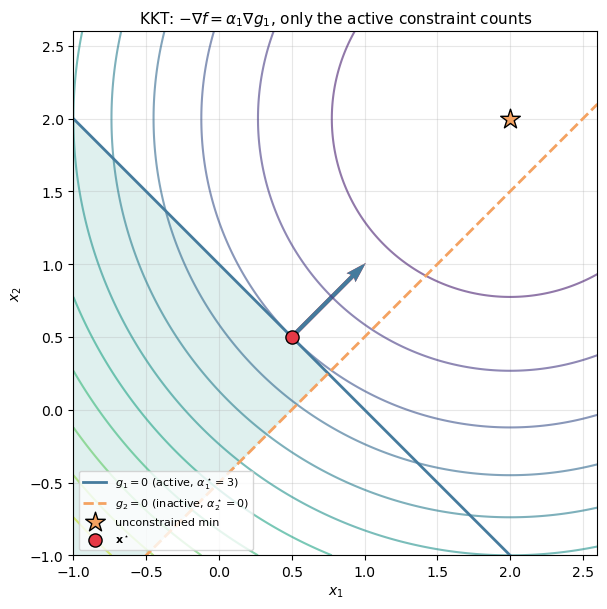

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, nnls

c = np.array([2.0, 2.0])
f      = lambda x: np.sum((x - c)**2)
grad_f = lambda x: 2*(x - c)
g_funcs = [lambda x: x[0] + x[1] - 1, lambda x: x[0] - x[1] - 0.5]
g_grads = [lambda x: np.array([1.0, 1.0]), lambda x: np.array([1.0, -1.0])]

res = minimize(f, x0=np.zeros(2), jac=grad_f, method='SLSQP',
               constraints=[{'type': 'ineq', 'fun': (lambda x, g=g: -g(x)), 'jac': (lambda x, dg=dg: -dg(x))}
                            for g, dg in zip(g_funcs, g_grads)],
               options={'ftol': 1e-12})
x_star = res.x

# Recover alpha >= 0 from stationarity  grad f + sum_i alpha_i grad g_i = 0  (non-negative least squares)
G = np.column_stack([dg(x_star) for dg in g_grads])
alpha_star, _ = nnls(G, -grad_f(x_star))

def check_kkt(x, alpha, tol=1e-6):
    # Return the four KKT residuals; all should be ~0 at the optimum.
    g_vals = np.array([g(x) for g in g_funcs])
    stat   = grad_f(x) + sum(a*dg(x) for a, dg in zip(alpha, g_grads))
    return {
        '1. stationarity  ||grad L||':      np.linalg.norm(stat),
        '2. primal feas.  max(g_i, 0)':     max(g_vals.max(), 0),
        '3. dual feas.    max(-alpha_i, 0)': max(-alpha.min(), 0),
        '4. compl. slack. max|alpha_i g_i|': np.abs(alpha * g_vals).max(),
    }

print(f"x*     = {np.round(x_star, 6)}")
print(f"g(x*)  = {np.round([g(x_star) for g in g_funcs], 6)}   (g1 active, g2 inactive)")
print(f"alpha* = {np.round(alpha_star, 6)}\n")
for k, v in check_kkt(x_star, alpha_star).items():
    print(f"  {k:36s} {v:.2e}")

# A feasible but NON-optimal point: both constraints are inactive there, yet stationarity can only be
# met with alpha > 0 -> complementary slackness is violated, so KKT certify that it is not optimal
x_bad = np.array([0.0, 0.5])
alpha_bad, _ = nnls(np.column_stack([dg(x_bad) for dg in g_grads]), -grad_f(x_bad))
print(f"\nNon-optimal feasible point {x_bad}:")
for k, v in check_kkt(x_bad, alpha_bad).items():
    print(f"  {k:36s} {v:.2e}")

xx, yy = np.meshgrid(np.linspace(-1, 2.6, 300), np.linspace(-1, 2.6, 300))
feasible = (xx + yy - 1 <= 0) & (xx - yy - 0.5 <= 0)
fig, ax = plt.subplots(figsize=(6.8, 6.2))
ax.contour(xx, yy, (xx - c[0])**2 + (yy - c[1])**2, levels=16, cmap='viridis', alpha=0.6)
ax.contourf(xx, yy, feasible, levels=[0.5, 1], colors=['#2A9D8F'], alpha=0.15)
t = np.linspace(-1, 2.6, 2)
ax.plot(t, 1 - t, '#457B9D', lw=2, label=r'$g_1=0$ (active, $\alpha_1^\star=3$)')
ax.plot(t, t - 0.5, '#F4A261', lw=2, linestyle='--', label=r'$g_2=0$ (inactive, $\alpha_2^\star=0$)')
ax.scatter(*c, marker='*', s=220, color='#F4A261', edgecolor='k', zorder=6, label='unconstrained min')
ax.scatter(*x_star, s=90, color='#E63946', edgecolor='k', zorder=7, label=r'$\mathbf{x}^\star$')
ax.quiver(*x_star, *(-grad_f(x_star)/np.linalg.norm(grad_f(x_star))), color='#E63946', scale=5, width=0.008)
ax.quiver(*x_star, *(g_grads[0](x_star)/np.sqrt(2)), color='#457B9D', scale=5, width=0.008)
ax.set_xlim(-1, 2.6); ax.set_ylim(-1, 2.6); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title(r'KKT: $-\nabla f=\alpha_1\nabla g_1$, only the active constraint counts', fontsize=11)
ax.legend(fontsize=8, loc='lower left'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
# Part II — Hyperplanes & Margin

---
## 5. Hyperplanes, Signed Distance and the $\pm1$ Label Convention

From now on we follow the SVM conventions of CS229 [1]:

* Labels $y\in\{-1,+1\}$ (not $\{0,1\}$ as in `07`), so that "correct side" is a single sign condition.
* The intercept is kept **separate**: parameters $(\mathbf{w},b)$, classifier $h_{\mathbf{w},b}(\mathbf{x})=\operatorname{sign}(\mathbf{w}^T\mathbf{x}+b)$. No probabilities: the SVM outputs a label directly.

### Geometry (recap of `03_linear_algebra_and_geometry`)

The hyperplane $\mathcal{H}=\{\mathbf{x}:\mathbf{w}^T\mathbf{x}+b=0\}$ has **normal vector** $\mathbf{w}$ (for any two points on $\mathcal{H}$, $\mathbf{w}^T(\mathbf{x}_1-\mathbf{x}_2)=0$). Write any point as its projection on $\mathcal{H}$ plus a step along the unit normal: $\mathbf{x}=\mathbf{x}_\perp+r\,\frac{\mathbf{w}}{\|\mathbf{w}\|}$. Applying $\mathbf{w}^T(\cdot)+b$ to both sides, with $\mathbf{w}^T\mathbf{x}_\perp+b=0$:

$$\boxed{r(\mathbf{x}) = \frac{\mathbf{w}^T\mathbf{x}+b}{\|\mathbf{w}\|}} \qquad\text{(signed distance: }r>0\text{ on the side }\mathbf{w}\text{ points to)}$$

Multiplying by the label turns it into "distance on the correct side":

$$y_i\,r(\mathbf{x}_i) = \frac{y_i(\mathbf{w}^T\mathbf{x}_i+b)}{\|\mathbf{w}\|} \;>0 \iff \mathbf{x}_i \text{ is correctly classified}$$

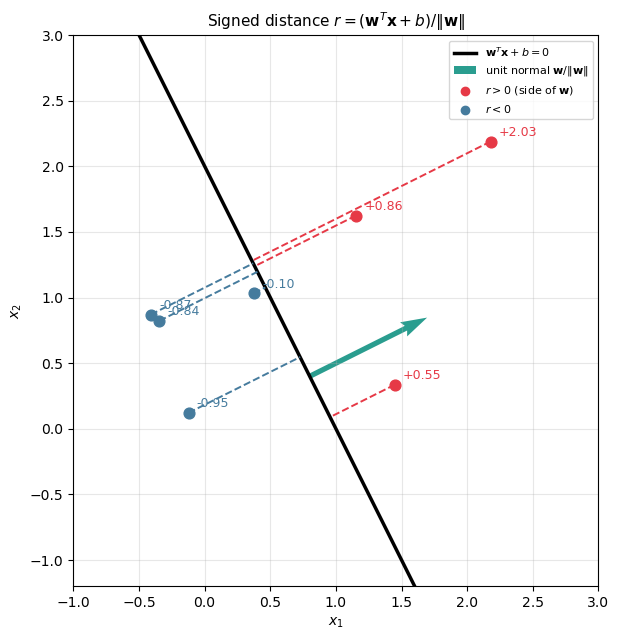

max |w^T x_perp + b|          : 8.881784197001252e-16
max | |r| - ||x - x_perp|| |  : 1.1102230246251565e-16


In [5]:
import numpy as np
import matplotlib.pyplot as plt

w, b = np.array([2.0, 1.0]), -2.0
w_hat = w / np.linalg.norm(w)

np.random.seed(3)
P = np.random.uniform(-0.5, 2.5, size=(7, 2))
r = (P @ w + b) / np.linalg.norm(w)            # signed distances
proj = P - r[:, None] * w_hat                   # orthogonal projections onto H

fig, ax = plt.subplots(figsize=(7.5, 6.5))
t = np.linspace(-1, 3, 2)
ax.plot(t, (-b - w[0]*t) / w[1], 'k', lw=2.5, label=r'$\mathbf{w}^T\mathbf{x}+b=0$')
x0 = -b * w / (w @ w)                           # point of H closest to the origin
ax.quiver(*x0, *w_hat, color='#2A9D8F', scale=4, width=0.01, label=r'unit normal $\mathbf{w}/\|\mathbf{w}\|$')
for p, q, ri in zip(P, proj, r):
    col = '#E63946' if ri > 0 else '#457B9D'
    ax.plot([p[0], q[0]], [p[1], q[1]], color=col, lw=1.4, linestyle='--')
    ax.scatter(*p, color=col, s=60, zorder=5)
    ax.annotate(f'{ri:+.2f}', p, textcoords='offset points', xytext=(6, 4), fontsize=9, color=col)
ax.scatter([], [], color='#E63946', label='$r>0$ (side of $\\mathbf{w}$)')
ax.scatter([], [], color='#457B9D', label='$r<0$')
ax.set_xlim(-1, 3); ax.set_ylim(-1.2, 3); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title(r'Signed distance $r=(\mathbf{w}^T\mathbf{x}+b)/\|\mathbf{w}\|$', fontsize=11)
ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Sanity check: projections lie on H, and |r| equals the Euclidean distance to the projection
print("max |w^T x_perp + b|          :", np.abs(proj @ w + b).max())
print("max | |r| - ||x - x_perp|| |  :", np.abs(np.abs(r) - np.linalg.norm(P - proj, axis=1)).max())

---
## 6. Functional vs. Geometric Margin

Given a training set $\{(\mathbf{x}_i,y_i)\}_{i=1}^N$ and a hyperplane $(\mathbf{w},b)$:

| | Per example | On the dataset | Scale-invariant? |
|---|---|---|---|
| **Functional margin** | $\hat\gamma_i = y_i(\mathbf{w}^T\mathbf{x}_i+b)$ | $\hat\gamma=\min_i\hat\gamma_i$ | **No**: $(\mathbf{w},b)\to(c\mathbf{w},cb)$ gives $\hat\gamma\to c\hat\gamma$ |
| **Geometric margin** | $\gamma_i = \dfrac{y_i(\mathbf{w}^T\mathbf{x}_i+b)}{\|\mathbf{w}\|}=\dfrac{\hat\gamma_i}{\|\mathbf{w}\|}$ | $\gamma=\min_i\gamma_i$ | **Yes** |

The functional margin is a measure of *confidence* ($\hat\gamma_i\gg0$: confidently correct — the same intuition as $\mathbf{w}^T\mathbf{x}\gg0$ in logistic regression), but since $\operatorname{sign}(c\,\mathbf{w}^T\mathbf{x}+cb)$ is the same classifier for every $c>0$, it can be inflated for free. The geometric margin is the actual Euclidean distance of the closest point to the boundary.

**Freedom of scale.** Because $(c\mathbf{w},cb)$ is the same hyperplane, we can **fix the scale** by requiring $\hat\gamma=1$, i.e. the closest points satisfy $y_i(\mathbf{w}^T\mathbf{x}_i+b)=1$. Then

$$\gamma=\frac{1}{\|\mathbf{w}\|}, \qquad \text{margin width (between the two parallel lines } \mathbf{w}^T\mathbf{x}+b=\pm1) = \frac{2}{\|\mathbf{w}\|}$$

Among all separating hyperplanes, which one has the largest $\gamma$? The plot below compares three of them.

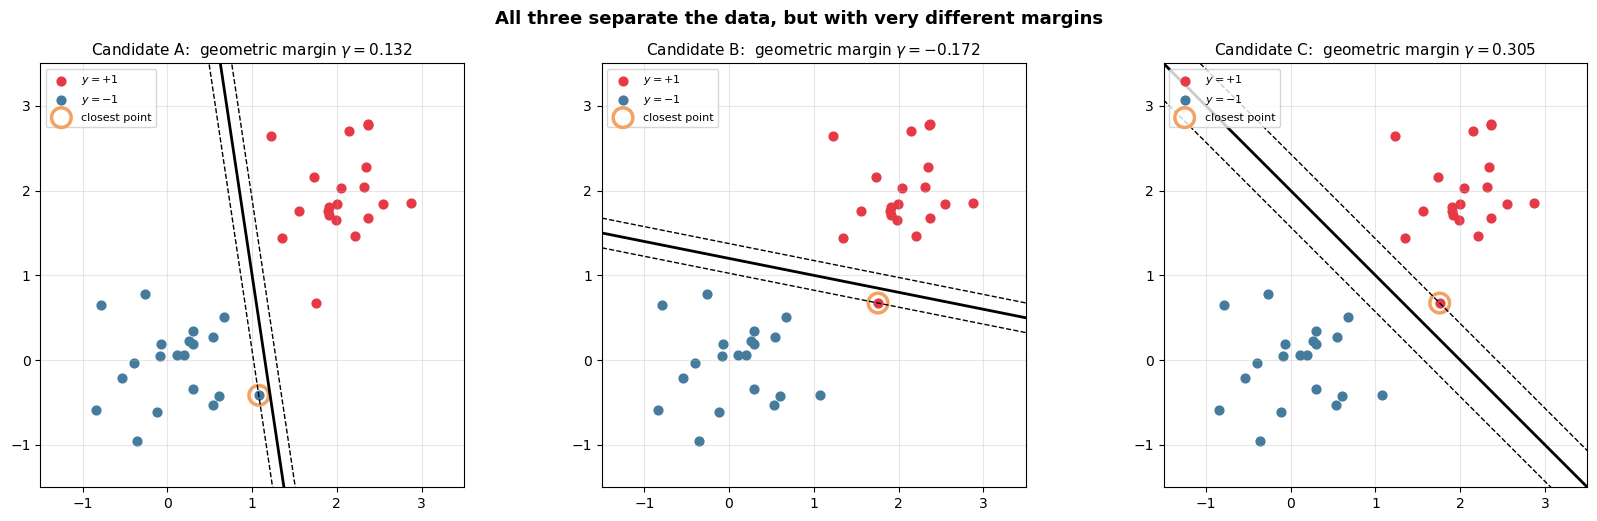

 scale c |  functional margin |  geometric margin
     0.5 |             0.2155 |            0.3048
       1 |             0.4311 |            0.3048
       2 |             0.8621 |            0.3048
      10 |             4.3106 |            0.3048
     100 |            43.1058 |            0.3048


In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(11)
Xp = np.random.multivariate_normal([2.0, 2.0], 0.25*np.eye(2), 20)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.25*np.eye(2), 20)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(20), -np.ones(20)])

def geometric_margin(w, b, X, y):
    return np.min(y * (X @ w + b)) / np.linalg.norm(w)

candidates = [(np.array([1.0, 0.15]), -1.15, 'Candidate A'),
              (np.array([0.2, 1.0]),  -1.2, 'Candidate B'),
              (np.array([1.0, 1.0]),  -2.0, 'Candidate C')]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
t = np.linspace(-1.5, 3.5, 2)
for ax, (w, b, name) in zip(axes, candidates):
    gamma = geometric_margin(w, b, X, y)
    # normalize so that the functional margin is 1  ->  lines w^T x + b = +-1
    s = 1.0 / np.min(y * (X @ w + b)); wn, bn = s*w, s*b
    ax.scatter(Xp[:, 0], Xp[:, 1], color='#E63946', s=40, label='$y=+1$')
    ax.scatter(Xn[:, 0], Xn[:, 1], color='#457B9D', s=40, label='$y=-1$')
    ax.plot(t, (-bn - wn[0]*t)/wn[1], 'k', lw=2)
    ax.plot(t, (1 - bn - wn[0]*t)/wn[1], 'k--', lw=1)
    ax.plot(t, (-1 - bn - wn[0]*t)/wn[1], 'k--', lw=1)
    closest = np.argmin(y * (X @ w + b))
    ax.scatter(*X[closest], s=200, facecolor='none', edgecolor='#F4A261', lw=2.5, label='closest point')
    ax.set_xlim(-1.5, 3.5); ax.set_ylim(-1.5, 3.5); ax.set_aspect('equal')
    ax.set_title(f'{name}:  geometric margin $\\gamma={gamma:.3f}$', fontsize=11)
    ax.legend(fontsize=8, loc='upper left'); ax.grid(True, alpha=0.3)
plt.suptitle('All three separate the data, but with very different margins', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

w, b = candidates[2][:2]
print(f"{'scale c':>8} | {'functional margin':>18} | {'geometric margin':>17}")
for cfac in [0.5, 1, 2, 10, 100]:
    fm = np.min(y * (X @ (cfac*w) + cfac*b))
    print(f"{cfac:>8} | {fm:>18.4f} | {geometric_margin(cfac*w, cfac*b, X, y):>17.4f}")

---
# Part III — Support Vector Machines

---
## 7. The Hard-Margin SVM: Primal Problem

We want the hyperplane with the **largest geometric margin** that separates the data:

$$\max_{\gamma,\mathbf{w},b}\ \gamma \quad\text{s.t.}\quad \frac{y_i(\mathbf{w}^T\mathbf{x}_i+b)}{\|\mathbf{w}\|}\ge\gamma\quad\forall i$$

This is non-convex as written. Two steps fix it:
1. Use the scale freedom of Section 6 to set the functional margin to $1$: the constraints become $y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1$ and $\gamma=1/\|\mathbf{w}\|$.
2. $\max 1/\|\mathbf{w}\| \iff \min\|\mathbf{w}\| \iff \min\tfrac12\|\mathbf{w}\|^2$ (monotone, differentiable, and the $\tfrac12$ simplifies derivatives).

$$\boxed{\min_{\mathbf{w},b}\ \frac12\|\mathbf{w}\|^2 \quad\text{s.t.}\quad y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1,\quad i=1,\dots,N}$$

A **convex quadratic program** (QP): quadratic objective, $N$ affine inequality constraints, $d+1$ variables. It has a unique $\mathbf{w}^\star$, and since the constraints are affine and the data are separable, **strong duality holds** (Section 3). In the language of Part I, the constraints are

$$g_i(\mathbf{w},b) = 1 - y_i(\mathbf{w}^T\mathbf{x}_i+b)\le0$$

Below we solve the primal directly with a generic QP solver (`SLSQP`) to have a reference solution.

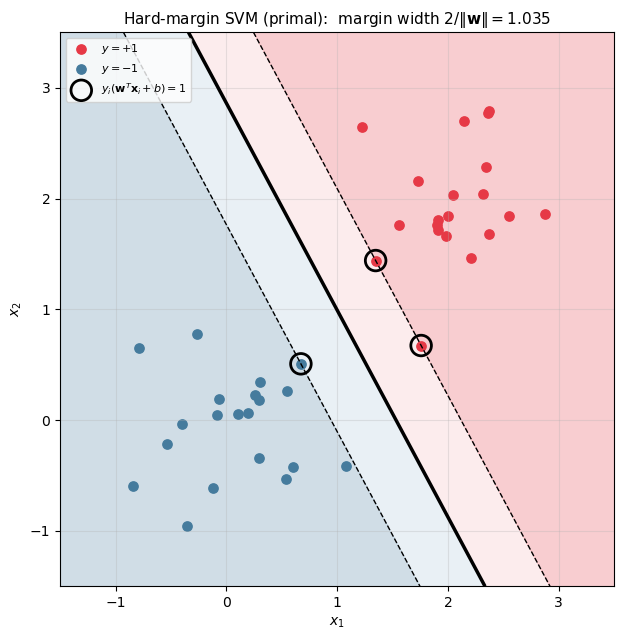

w = [1.7042 0.9122], b = -2.6098
geometric margin gamma = 1/||w|| = 0.5173
min functional margin  = 1.000000   (should be 1)
points exactly on the margin: 3 of 40


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(11)
Xp = np.random.multivariate_normal([2.0, 2.0], 0.25*np.eye(2), 20)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.25*np.eye(2), 20)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(20), -np.ones(20)])

def svm_primal_hard(X, y):
    # min 1/2 ||w||^2  s.t.  y_i (w^T x_i + b) >= 1.  Variables v = [w, b].
    N, d = X.shape
    obj  = lambda v: 0.5 * v[:d] @ v[:d]
    jac  = lambda v: np.concatenate([v[:d], [0.0]])
    A    = y[:, None] * np.hstack([X, np.ones((N, 1))])   # row i: y_i [x_i, 1]
    cons = {'type': 'ineq', 'fun': lambda v: A @ v - 1, 'jac': lambda v: A}
    res  = minimize(obj, np.zeros(d + 1), jac=jac, constraints=[cons], method='SLSQP',
                    options={'ftol': 1e-12, 'maxiter': 500})
    return res.x[:d], res.x[d]

w, b = svm_primal_hard(X, y)
fm = y * (X @ w + b)

fig, ax = plt.subplots(figsize=(7, 6.5))
xx, yy = np.meshgrid(np.linspace(-1.5, 3.5, 300), np.linspace(-1.5, 3.5, 300))
F = w[0]*xx + w[1]*yy + b
ax.contourf(xx, yy, F, levels=[-100, -1, 0, 1, 100], colors=['#457B9D', '#a8c5da', '#f4b6bb', '#E63946'], alpha=0.25)
ax.contour(xx, yy, F, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[1, 2.5, 1])
ax.scatter(Xp[:, 0], Xp[:, 1], color='#E63946', s=45, label='$y=+1$')
ax.scatter(Xn[:, 0], Xn[:, 1], color='#457B9D', s=45, label='$y=-1$')
on_margin = np.isclose(fm, 1, atol=1e-5)
ax.scatter(X[on_margin, 0], X[on_margin, 1], s=220, facecolor='none', edgecolor='k', lw=2,
           label=r'$y_i(\mathbf{w}^T\mathbf{x}_i+b)=1$')
ax.set_aspect('equal'); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title(f'Hard-margin SVM (primal):  margin width $2/\\|\\mathbf{{w}}\\|={2/np.linalg.norm(w):.3f}$', fontsize=11)
ax.legend(fontsize=8, loc='upper left'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f"w = {np.round(w, 4)}, b = {b:.4f}")
print(f"geometric margin gamma = 1/||w|| = {1/np.linalg.norm(w):.4f}")
print(f"min functional margin  = {fm.min():.6f}   (should be 1)")
print(f"points exactly on the margin: {on_margin.sum()} of {len(y)}")

---
## 8. The Lagrangian Dual of the SVM

Apply Part I to the primal of Section 7, with one multiplier $\alpha_i\ge0$ per constraint $g_i=1-y_i(\mathbf{w}^T\mathbf{x}_i+b)\le0$:

$$\mathcal{L}(\mathbf{w},b,\boldsymbol\alpha) = \frac12\|\mathbf{w}\|^2 - \sum_{i=1}^N\alpha_i\big[y_i(\mathbf{w}^T\mathbf{x}_i+b)-1\big]$$

### Step 1 — Minimize over the primal variables (unconstrained!)

$$\nabla_\mathbf{w}\mathcal{L} = \mathbf{w}-\sum_i\alpha_iy_i\mathbf{x}_i = \mathbf{0} \;\Longrightarrow\; \boxed{\mathbf{w}=\sum_{i=1}^N\alpha_iy_i\mathbf{x}_i}$$

$$\frac{\partial\mathcal{L}}{\partial b} = -\sum_i\alpha_iy_i = 0 \;\Longrightarrow\; \boxed{\sum_{i=1}^N\alpha_iy_i=0}$$

### Step 2 — Substitute back

$\frac12\|\mathbf{w}\|^2=\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\mathbf{x}_i^T\mathbf{x}_j$, and $\sum_i\alpha_iy_i\mathbf{w}^T\mathbf{x}_i=\|\mathbf{w}\|^2$, while the $b$-term vanishes because $\sum_i\alpha_iy_i=0$:

$$\boxed{\max_{\boldsymbol\alpha}\ W(\boldsymbol\alpha)=\sum_{i=1}^N\alpha_i-\frac12\sum_{i,j=1}^N\alpha_i\alpha_jy_iy_j\,\mathbf{x}_i^T\mathbf{x}_j \quad\text{s.t.}\quad \alpha_i\ge0,\ \ \sum_{i=1}^N\alpha_iy_i=0}$$

In matrix form, with $\mathbf{Q}_{ij}=y_iy_j\mathbf{x}_i^T\mathbf{x}_j$ (i.e. $\mathbf{Q}=(\mathbf{y}\mathbf{y}^T)\odot\mathbf{X}\mathbf{X}^T$, a PSD matrix): $\ \min_{\boldsymbol\alpha}\tfrac12\boldsymbol\alpha^T\mathbf{Q}\boldsymbol\alpha-\mathbf{1}^T\boldsymbol\alpha$.

### Three observations

1. **Variables:** the dual has $N$ variables (one per example), the primal $d+1$. Useful when $d\gg N$ — or $d=\infty$.
2. **Inner products only:** the data appear *exclusively* through $\mathbf{x}_i^T\mathbf{x}_j$, and the prediction too:
   $$f(\mathbf{x})=\mathbf{w}^T\mathbf{x}+b=\sum_i\alpha_iy_i\,\mathbf{x}_i^T\mathbf{x}+b$$
   This is the door to the kernel trick (Part V).
3. **Strong duality** means $W(\boldsymbol\alpha^\star)=\frac12\|\mathbf{w}^\star\|^2$: we can check the solver by comparing the two objectives.

w (primal) = [1.70424 0.91219],  b = -2.60979
w (dual)   = [1.70424 0.91219],  b = -2.60979
primal objective 1/2||w||^2 = 1.868266
dual objective   W(alpha)   = 1.868266   (strong duality: equal)
sum_i alpha_i y_i           = -1.20e-14


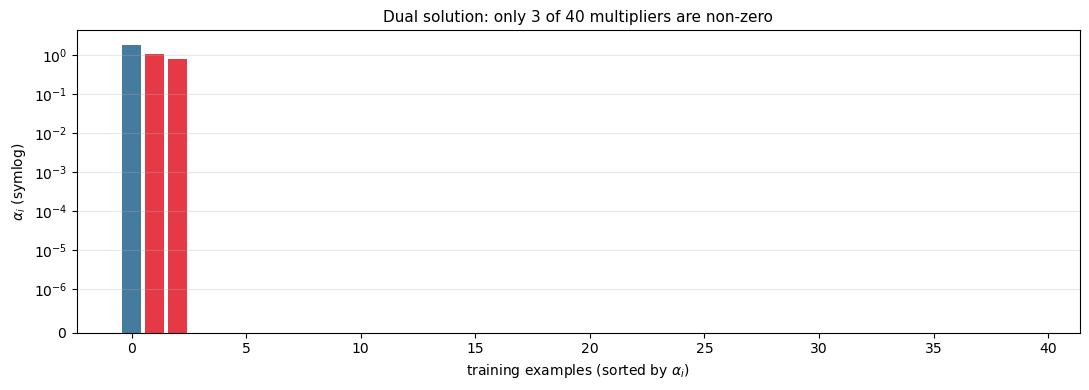

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(11)
Xp = np.random.multivariate_normal([2.0, 2.0], 0.25*np.eye(2), 20)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.25*np.eye(2), 20)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(20), -np.ones(20)])

def svm_primal_hard(X, y):
    N, d = X.shape
    A = y[:, None] * np.hstack([X, np.ones((N, 1))])
    res = minimize(lambda v: 0.5 * v[:d] @ v[:d], np.zeros(d + 1),
                   jac=lambda v: np.concatenate([v[:d], [0.0]]),
                   constraints=[{'type': 'ineq', 'fun': lambda v: A @ v - 1, 'jac': lambda v: A}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 500})
    return res.x[:d], res.x[d]

def svm_dual(K, y, C=None):
    # min 1/2 a^T Q a - 1^T a   s.t.  0 <= a_i (<= C),  sum a_i y_i = 0.   Q = (y y^T) * K
    N = len(y)
    Q = np.outer(y, y) * K
    res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(N),
                   jac=lambda a: Q @ a - 1,
                   bounds=[(0, C)] * N,
                   constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})
    return res.x

K = X @ X.T                         # linear kernel: Gram matrix of inner products
alpha = svm_dual(K, y)
w_dual = (alpha * y) @ X            # w = sum_i alpha_i y_i x_i
sv = alpha > 1e-6 * alpha.max()
b_dual = np.mean(y[sv] - X[sv] @ w_dual)

w_primal, b_primal = svm_primal_hard(X, y)
Q = np.outer(y, y) * K
print(f"w (primal) = {np.round(w_primal, 5)},  b = {b_primal:.5f}")
print(f"w (dual)   = {np.round(w_dual, 5)},  b = {b_dual:.5f}")
print(f"primal objective 1/2||w||^2 = {0.5 * w_primal @ w_primal:.6f}")
print(f"dual objective   W(alpha)   = {alpha.sum() - 0.5 * alpha @ Q @ alpha:.6f}   (strong duality: equal)")
print(f"sum_i alpha_i y_i           = {alpha @ y:.2e}")

fig, ax = plt.subplots(figsize=(11, 4))
order = np.argsort(-alpha)
ax.bar(np.arange(len(y)), alpha[order], color=np.where(y[order] > 0, '#E63946', '#457B9D'))
ax.set_yscale('symlog', linthresh=1e-6)
ax.set_xlabel('training examples (sorted by $\\alpha_i$)'); ax.set_ylabel(r'$\alpha_i$ (symlog)')
ax.set_title(f'Dual solution: only {sv.sum()} of {len(y)} multipliers are non-zero', fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

---
## 9. Implementation Remark: $\alpha_i>0 \iff$ Support Vector

This is the practical payoff of the KKT conditions. For the SVM the four conditions of Section 4 read:

| KKT | SVM form |
|-----|----------|
| Stationarity | $\mathbf{w}=\sum_i\alpha_iy_i\mathbf{x}_i,\quad \sum_i\alpha_iy_i=0$ |
| Primal feasibility | $y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1$ |
| Dual feasibility | $\alpha_i\ge0$ |
| **Complementary slackness** | $\alpha_i\big[y_i(\mathbf{w}^T\mathbf{x}_i+b)-1\big]=0$ |

Complementary slackness splits the training set in two:

$$\alpha_i>0 \;\Longrightarrow\; y_i(\mathbf{w}^T\mathbf{x}_i+b)=1 \quad\text{(the point lies exactly on the margin: a **support vector**)}$$
$$y_i(\mathbf{w}^T\mathbf{x}_i+b)>1 \;\Longrightarrow\; \alpha_i=0 \quad\text{(the point does not appear in } \mathbf{w}=\textstyle\sum_i\alpha_iy_i\mathbf{x}_i)$$

### Consequences for the implementation

1. **Identify the support vectors** after solving the dual: $\mathcal{S}=\{i:\alpha_i>0\}$. Numerically $\alpha_i$ is never exactly $0$, so use a tolerance relative to the scale of the solution, e.g. $\alpha_i>10^{-6}\max_j\alpha_j$.
2. **Compute $b$** from the support vectors: for any $s\in\mathcal{S}$, $y_s(\mathbf{w}^T\mathbf{x}_s+b)=1$ and $y_s^2=1$ give $b=y_s-\mathbf{w}^T\mathbf{x}_s$. Average over all $s\in\mathcal{S}$ for numerical stability:
   $$b=\frac{1}{|\mathcal{S}|}\sum_{s\in\mathcal{S}}\Big(y_s-\sum_{i\in\mathcal{S}}\alpha_iy_i\,\mathbf{x}_i^T\mathbf{x}_s\Big)$$
3. **Sparse prediction:** $f(\mathbf{x})=\sum_{i\in\mathcal{S}}\alpha_iy_i\,\mathbf{x}_i^T\mathbf{x}+b$ — store and evaluate only $|\mathcal{S}|\ll N$ points.
4. **Robustness to the rest of the data:** removing any point with $\alpha_i=0$ and retraining gives **exactly the same** classifier. Removing a support vector may change it.

The cell below checks all four points.

Support vectors (alpha_i > 0):
   i= 1  y=+1  alpha=1.0817   y_i f(x_i) = 1.000000
   i= 7  y=+1  alpha=0.7866   y_i f(x_i) = 1.000000
   i=37  y=-1  alpha=1.8683   y_i f(x_i) = 1.000000

non-SVs: min y_i f(x_i) = 1.1503 (> 1),  max alpha = 2.3e-15
max |alpha_i (y_i f(x_i) - 1)| over all i = 3.1e-08   (complementary slackness)

full data        : w = [1.7042 0.9122], b = -2.6098
SVs only (3 pts) : w = [1.7042 0.9122], b = -2.6098   -> identical
without SV #1    : w = [1.0188 1.4081], b = -2.4006   -> changed


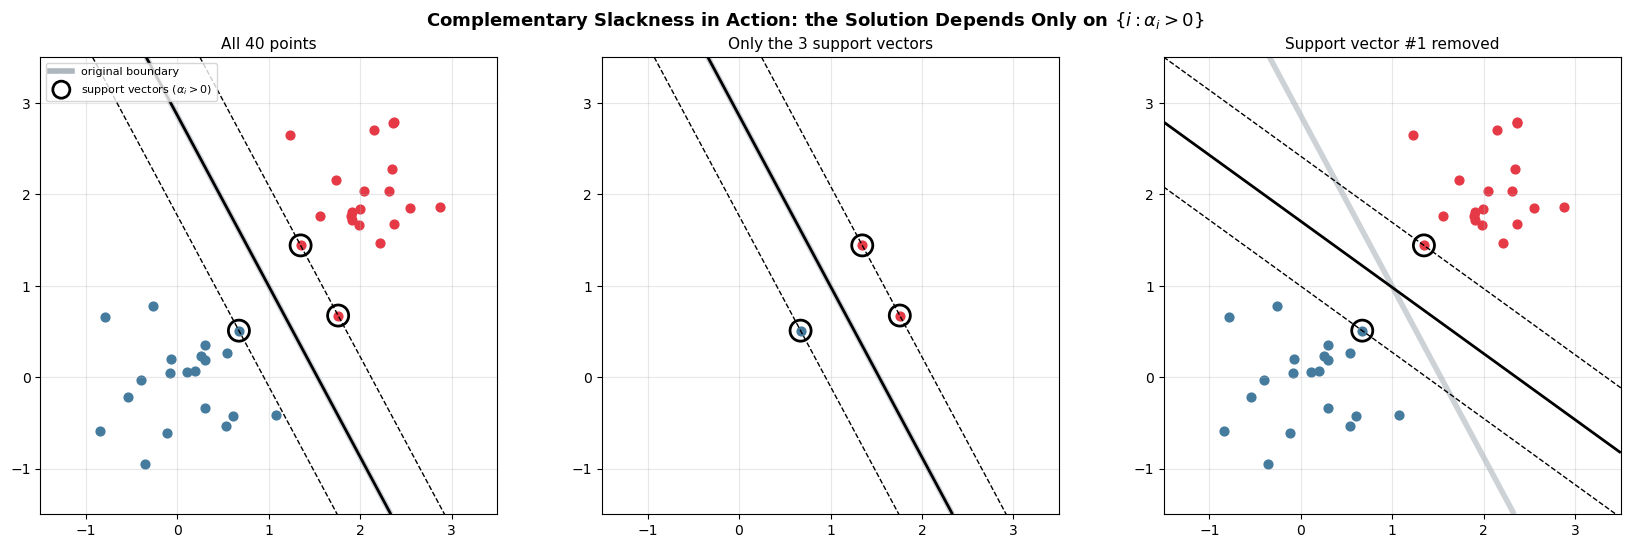

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(11)
Xp = np.random.multivariate_normal([2.0, 2.0], 0.25*np.eye(2), 20)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.25*np.eye(2), 20)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(20), -np.ones(20)])

def svm_dual(K, y, C=None):
    N = len(y); Q = np.outer(y, y) * K
    res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(N), jac=lambda a: Q @ a - 1,
                   bounds=[(0, C)] * N,
                   constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})
    return res.x

def fit_linear_svm(X, y, rel_tol=1e-6):
    alpha = svm_dual(X @ X.T, y)
    sv = alpha > rel_tol * alpha.max()                 # implementation remark (1)
    w = (alpha[sv] * y[sv]) @ X[sv]                    # only SVs contribute
    b = np.mean(y[sv] - X[sv] @ w)                     # implementation remark (2)
    return w, b, alpha, sv

w, b, alpha, sv = fit_linear_svm(X, y)
fm = y * (X @ w + b)

print("Support vectors (alpha_i > 0):")
for i in np.where(sv)[0]:
    print(f"   i={i:2d}  y={int(y[i]):+d}  alpha={alpha[i]:.4f}   y_i f(x_i) = {fm[i]:.6f}")
print(f"\nnon-SVs: min y_i f(x_i) = {fm[~sv].min():.4f} (> 1),  max alpha = {alpha[~sv].max():.1e}")
print(f"max |alpha_i (y_i f(x_i) - 1)| over all i = {np.abs(alpha * (fm - 1)).max():.1e}   (complementary slackness)")

# (4) retrain on the support vectors only, and on the data without one support vector
w_sv, b_sv, *_ = fit_linear_svm(X[sv], y[sv])
drop = np.where(sv)[0][0]
keep = np.ones(len(y), bool); keep[drop] = False
w_drop, b_drop, _, sv_drop = fit_linear_svm(X[keep], y[keep])
print(f"\nfull data        : w = {np.round(w, 4)}, b = {b:.4f}")
print(f"SVs only ({sv.sum()} pts) : w = {np.round(w_sv, 4)}, b = {b_sv:.4f}   -> identical")
print(f"without SV #{drop:<4d} : w = {np.round(w_drop, 4)}, b = {b_drop:.4f}   -> changed")

xx, yy = np.meshgrid(np.linspace(-1.5, 3.5, 300), np.linspace(-1.5, 3.5, 300))
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
panels = [(X, y, w, b, sv, 'All 40 points'),
          (X[sv], y[sv], w_sv, b_sv, np.ones(sv.sum(), bool), f'Only the {sv.sum()} support vectors'),
          (X[keep], y[keep], w_drop, b_drop, sv_drop, f'Support vector #{drop} removed')]
for ax, (Xi, yi, wi, bi, svi, title) in zip(axes, panels):
    F = wi[0]*xx + wi[1]*yy + bi
    ax.contour(xx, yy, w[0]*xx + w[1]*yy + b, levels=[0], colors='#adb5bd', linewidths=4, alpha=0.6)
    ax.contour(xx, yy, F, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[1, 2, 1])
    ax.scatter(Xi[yi > 0, 0], Xi[yi > 0, 1], color='#E63946', s=40)
    ax.scatter(Xi[yi < 0, 0], Xi[yi < 0, 1], color='#457B9D', s=40)
    ax.scatter(Xi[svi, 0], Xi[svi, 1], s=230, facecolor='none', edgecolor='k', lw=2)
    ax.set_title(title, fontsize=11); ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
axes[0].plot([], [], color='#adb5bd', lw=4, label='original boundary')
axes[0].scatter([], [], s=150, facecolor='none', edgecolor='k', lw=2, label=r'support vectors ($\alpha_i>0$)')
axes[0].legend(fontsize=8, loc='upper left')
plt.suptitle(r'Complementary Slackness in Action: the Solution Depends Only on $\{i:\alpha_i>0\}$', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 10. Soft-Margin SVM: Slack Variables and the Box Constraint

Real data are rarely separable: the hard-margin primal is then **infeasible**, and even when it is feasible a single outlier can force a tiny margin. Allow each constraint to be violated by a **slack** $\xi_i\ge0$, at a price $C$ per unit:

$$\boxed{\min_{\mathbf{w},b,\boldsymbol\xi}\ \frac12\|\mathbf{w}\|^2+C\sum_{i=1}^N\xi_i \quad\text{s.t.}\quad y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1-\xi_i,\ \ \xi_i\ge0}$$

| $\xi_i$ | Meaning |
|---|---|
| $\xi_i=0$ | correct side of the margin |
| $0<\xi_i\le1$ | inside the margin, still correctly classified |
| $\xi_i>1$ | misclassified |

### Dual

Two families of constraints $\Rightarrow$ two families of multipliers: $\alpha_i\ge0$ for the margin constraints, $\mu_i\ge0$ for $\xi_i\ge0$:

$$\mathcal{L}=\frac12\|\mathbf{w}\|^2+C\sum_i\xi_i-\sum_i\alpha_i\big[y_i(\mathbf{w}^T\mathbf{x}_i+b)-1+\xi_i\big]-\sum_i\mu_i\xi_i$$

The stationarity conditions in $\mathbf{w}$ and $b$ are unchanged. The new one is

$$\frac{\partial\mathcal{L}}{\partial\xi_i}=C-\alpha_i-\mu_i=0 \;\Longrightarrow\; \mu_i=C-\alpha_i\ge0 \;\Longrightarrow\; \alpha_i\le C$$

Substituting, the $\xi_i$ terms cancel and the dual is **identical to the hard-margin dual except for a box constraint**:

$$\boxed{\max_{\boldsymbol\alpha}\ \sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\,\mathbf{x}_i^T\mathbf{x}_j \quad\text{s.t.}\quad 0\le\alpha_i\le C,\ \ \sum_i\alpha_iy_i=0}$$

### The Remark of Section 9, Extended: Three Kinds of Points

Complementary slackness now gives two products: $\alpha_i\big[y_if(\mathbf{x}_i)-1+\xi_i\big]=0$ and $\mu_i\xi_i=(C-\alpha_i)\xi_i=0$.

| Multiplier | KKT implication | Position |
|---|---|---|
| $\alpha_i=0$ | $\mu_i=C>0\Rightarrow\xi_i=0$, $\ y_if(\mathbf{x}_i)\ge1$ | outside or on the margin — **not** a support vector |
| $0<\alpha_i<C$ | $\mu_i>0\Rightarrow\xi_i=0$ and $y_if(\mathbf{x}_i)=1$ | **exactly on the margin** (*free* / *margin* SV) |
| $\alpha_i=C$ | $\xi_i\ge0$, $\ y_if(\mathbf{x}_i)=1-\xi_i\le1$ | **inside the margin or misclassified** (*bound* SV) |

**Implementation:** compute $b$ by averaging $y_s-\mathbf{w}^T\mathbf{x}_s$ over the **free** support vectors only ($0<\alpha_s<C$, up to tolerance), because only those are guaranteed to satisfy $y_sf(\mathbf{x}_s)=1$.

> **Aside — the hinge loss.** At the optimum each slack is as small as allowed: $\xi_i=\max\big(0,\,1-y_if(\mathbf{x}_i)\big)$. Substituting gives the unconstrained form
> $$\min_{\mathbf{w},b}\ \frac12\|\mathbf{w}\|^2+C\sum_i\max\big(0,\,1-y_i(\mathbf{w}^T\mathbf{x}_i+b)\big),$$
> i.e. **regularized ERM** (`01`) with the **hinge loss** — the SVM counterpart of $L_2$-regularized cross-entropy in `07`, Section 10.

C = 1.0:  w = [1.706  1.6953], b = -2.4970
  alpha = 0      (non-SV)   :  63 points,  min y f(x) = 1.0875  (>= 1)
  0 < alpha < C  (free SV)  :   3 points,  y f(x) in [1.0000, 1.0000]  (= 1)
  alpha = C      (bound SV) :  14 points,  max y f(x) = 0.9257  (<= 1)
  misclassified (xi > 1)    :   4 points
  primal objective 1/2||w||^2 + C sum xi = 12.28463
  dual objective                          = 12.28463


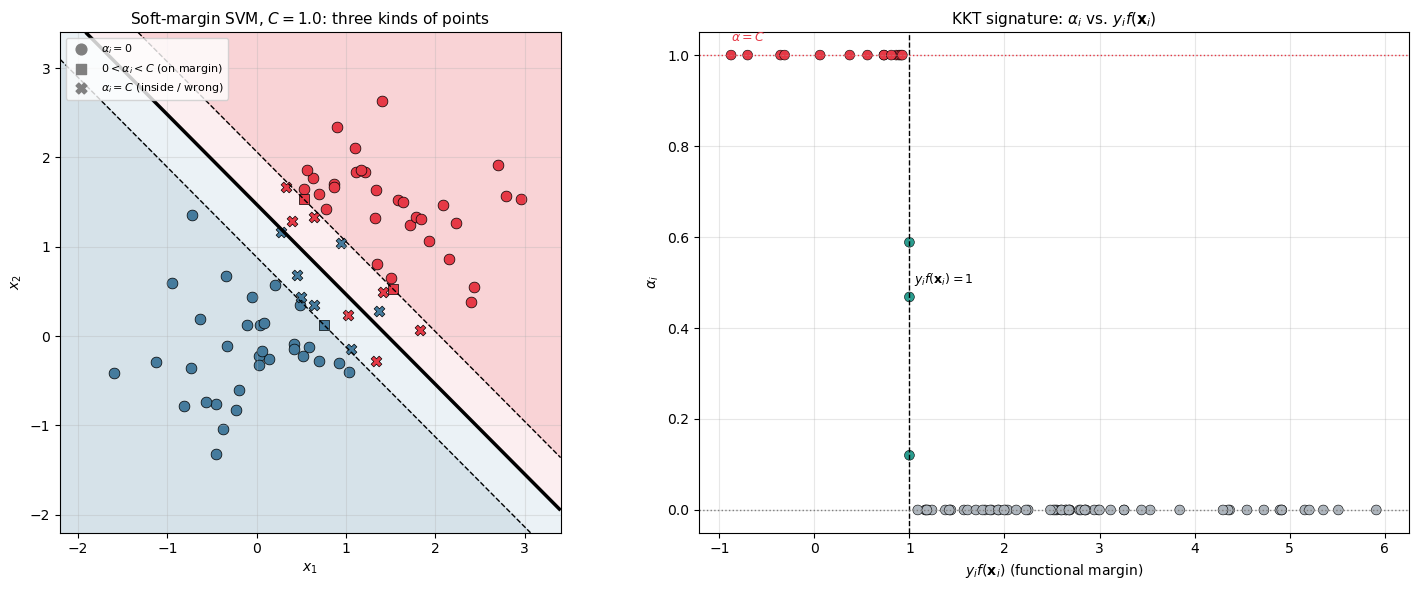

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(4)
N = 40
Xp = np.random.multivariate_normal([1.3, 1.3], 0.45*np.eye(2), N)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.45*np.eye(2), N)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(N), -np.ones(N)])

def svm_dual(K, y, C=None):
    n = len(y); Q = np.outer(y, y) * K
    res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(n), jac=lambda a: Q @ a - 1,
                   bounds=[(0, C)] * n,
                   constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})
    return res.x

def fit_soft_svm(X, y, C, tol=1e-5):
    alpha = svm_dual(X @ X.T, y, C)
    sv    = alpha > tol * C
    free  = sv & (alpha < C * (1 - tol))
    w = (alpha[sv] * y[sv]) @ X[sv]
    ref = free if free.any() else sv          # b from free SVs (fallback: all SVs)
    b = np.mean(y[ref] - X[ref] @ w)
    return w, b, alpha, sv, free

C = 1.0
w, b, alpha, sv, free = fit_soft_svm(X, y, C)
bound = sv & ~free
yf = y * (X @ w + b)
xi = np.maximum(0, 1 - yf)

print(f"C = {C}:  w = {np.round(w, 4)}, b = {b:.4f}")
print(f"  alpha = 0      (non-SV)   : {np.sum(~sv):3d} points,  min y f(x) = {yf[~sv].min():.4f}  (>= 1)")
print(f"  0 < alpha < C  (free SV)  : {np.sum(free):3d} points,  y f(x) in [{yf[free].min():.4f}, {yf[free].max():.4f}]  (= 1)")
print(f"  alpha = C      (bound SV) : {np.sum(bound):3d} points,  max y f(x) = {yf[bound].max():.4f}  (<= 1)")
print(f"  misclassified (xi > 1)    : {np.sum(xi > 1):3d} points")
print(f"  primal objective 1/2||w||^2 + C sum xi = {0.5*w@w + C*xi.sum():.5f}")
Q = np.outer(y, y) * (X @ X.T)
print(f"  dual objective                          = {alpha.sum() - 0.5*alpha@Q@alpha:.5f}")

xx, yy = np.meshgrid(np.linspace(-2.2, 3.4, 300), np.linspace(-2.2, 3.4, 300))
F = w[0]*xx + w[1]*yy + b
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ax.contourf(xx, yy, F, levels=[-100, -1, 0, 1, 100], colors=['#457B9D', '#a8c5da', '#f4b6bb', '#E63946'], alpha=0.22)
ax.contour(xx, yy, F, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[1, 2.5, 1])
for mask, mk, lab in [(~sv, 'o', r'$\alpha_i=0$'), (free, 's', r'$0<\alpha_i<C$ (on margin)'), (bound, 'X', r'$\alpha_i=C$ (inside / wrong)')]:
    ax.scatter(X[mask & (y > 0), 0], X[mask & (y > 0), 1], marker=mk, color='#E63946', s=60, edgecolor='k', lw=0.5)
    ax.scatter(X[mask & (y < 0), 0], X[mask & (y < 0), 1], marker=mk, color='#457B9D', s=60, edgecolor='k', lw=0.5)
    ax.scatter([], [], marker=mk, color='gray', s=60, label=lab)
ax.set_aspect('equal'); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title(f'Soft-margin SVM, $C={C}$: three kinds of points', fontsize=11)
ax.legend(fontsize=8, loc='upper left'); ax.grid(True, alpha=0.3)

ax = axes[1]
cols = np.where(~sv, '#adb5bd', np.where(free, '#2A9D8F', '#E63946'))
ax.scatter(yf, alpha, c=cols, s=50, edgecolor='k', lw=0.4)
ax.axvline(1, color='k', lw=1, linestyle='--'); ax.axhline(C, color='#E63946', lw=1, linestyle=':')
ax.axhline(0, color='gray', lw=1, linestyle=':')
ax.text(1.05, C*0.5, r'$y_i f(\mathbf{x}_i)=1$', fontsize=9)
ax.text(yf.min(), C*1.03, '$\\alpha=C$', fontsize=9, color='#E63946')
ax.set_xlabel(r'$y_i f(\mathbf{x}_i)$ (functional margin)'); ax.set_ylabel(r'$\alpha_i$')
ax.set_title(r'KKT signature: $\alpha_i$ vs. $y_i f(\mathbf{x}_i)$', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 11. The Role of $C$

$C$ trades **margin width** against **training violations**:

| $C$ | Effect | Analogy |
|---|---|---|
| small | violations are cheap $\Rightarrow$ wide margin, many support vectors, smoother boundary | strong regularization (large $\lambda$ in `06`/`07`) |
| large | violations are expensive $\Rightarrow$ narrow margin, few support vectors | weak regularization; $C\to\infty$ recovers the hard margin |

From the hinge-loss form, $C$ plays the role of $1/\lambda$: it is a **hyperparameter**, chosen by cross-validation like the polynomial degree or $\lambda$ in previous notebooks.

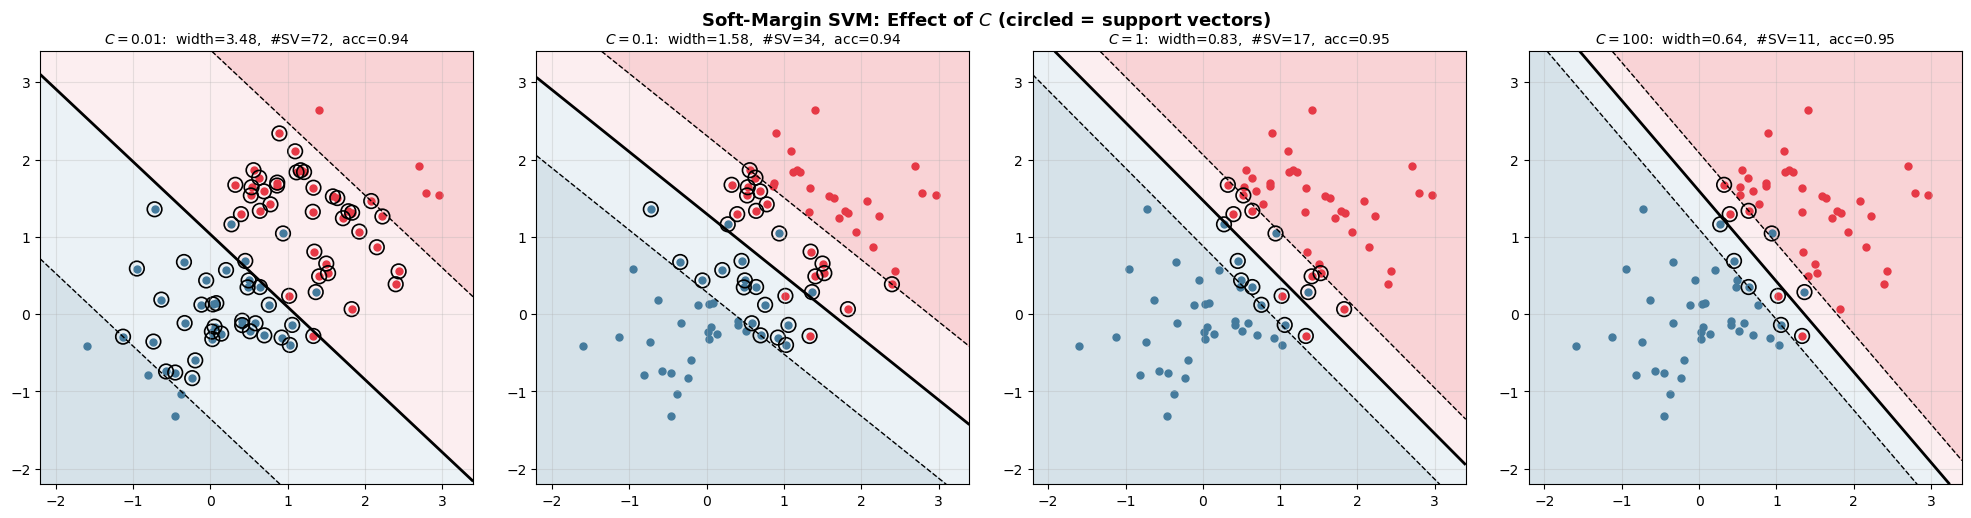

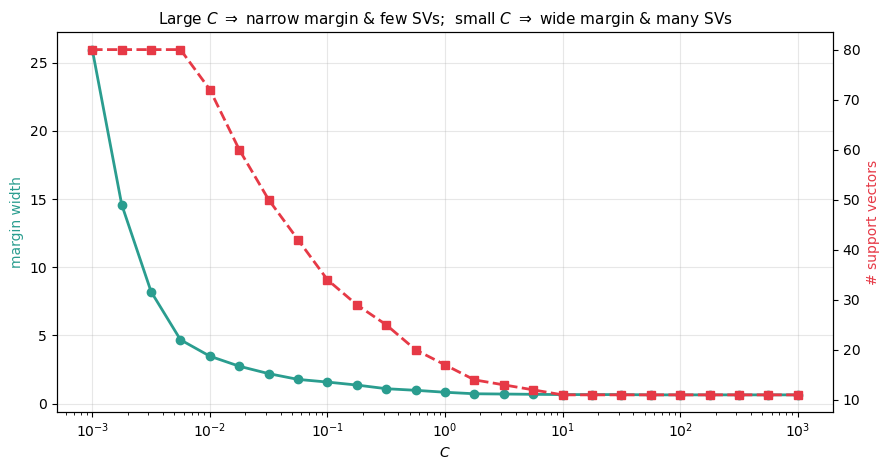

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(4)
N = 40
Xp = np.random.multivariate_normal([1.3, 1.3], 0.45*np.eye(2), N)
Xn = np.random.multivariate_normal([0.0, 0.0], 0.45*np.eye(2), N)
X  = np.vstack([Xp, Xn]); y = np.concatenate([np.ones(N), -np.ones(N)])

def svm_dual(K, y, C=None):
    n = len(y); Q = np.outer(y, y) * K
    res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(n), jac=lambda a: Q @ a - 1,
                   bounds=[(0, C)] * n,
                   constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 1000})
    return res.x

def fit_soft_svm(X, y, C, tol=1e-5):
    alpha = svm_dual(X @ X.T, y, C)
    sv = alpha > tol * C; free = sv & (alpha < C * (1 - tol))
    w = (alpha[sv] * y[sv]) @ X[sv]
    ref = free if free.any() else sv
    return w, np.mean(y[ref] - X[ref] @ w), alpha, sv

xx, yy = np.meshgrid(np.linspace(-2.2, 3.4, 250), np.linspace(-2.2, 3.4, 250))
C_show = [0.01, 0.1, 1, 100]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, C in zip(axes, C_show):
    w, b, alpha, sv = fit_soft_svm(X, y, C)
    F = w[0]*xx + w[1]*yy + b
    ax.contourf(xx, yy, F, levels=[-100, -1, 0, 1, 100], colors=['#457B9D', '#a8c5da', '#f4b6bb', '#E63946'], alpha=0.22)
    ax.contour(xx, yy, F, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[1, 2, 1])
    ax.scatter(X[y > 0, 0], X[y > 0, 1], color='#E63946', s=25)
    ax.scatter(X[y < 0, 0], X[y < 0, 1], color='#457B9D', s=25)
    ax.scatter(X[sv, 0], X[sv, 1], s=110, facecolor='none', edgecolor='k', lw=1.2)
    acc = np.mean(np.sign(X @ w + b) == y)
    ax.set_title(f'$C={C}$:  width={2/np.linalg.norm(w):.2f},  #SV={sv.sum()},  acc={acc:.2f}', fontsize=10)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
plt.suptitle('Soft-Margin SVM: Effect of $C$ (circled = support vectors)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

C_grid = np.logspace(-3, 3, 25)
widths, n_sv, train_err = [], [], []
for C in C_grid:
    w, b, alpha, sv = fit_soft_svm(X, y, C)
    widths.append(2/np.linalg.norm(w)); n_sv.append(sv.sum()); train_err.append(np.mean(np.sign(X @ w + b) != y))

fig, ax1 = plt.subplots(figsize=(9, 4.8))
ax1.semilogx(C_grid, widths, 'o-', color='#2A9D8F', lw=2, label='margin width $2/\\|\\mathbf{w}\\|$')
ax1.set_xlabel('$C$'); ax1.set_ylabel('margin width', color='#2A9D8F'); ax1.grid(True, alpha=0.3)
ax2 = ax1.twinx()
ax2.semilogx(C_grid, n_sv, 's--', color='#E63946', lw=2, label='# support vectors')
ax2.set_ylabel('# support vectors', color='#E63946')
ax1.set_title('Large $C$ $\\Rightarrow$ narrow margin & few SVs;  small $C$ $\\Rightarrow$ wide margin & many SVs', fontsize=11)
plt.tight_layout(); plt.show()

---
# Part IV — Remark: VC Dimension and the Margin

---
## 12. Shattering by Hyperplanes (recap of `02`)

Recall from `02_pac_and_vc_dimensions`:

* A hypothesis class $\mathcal{H}$ **shatters** a set $C=\{\mathbf{x}_1,\dots,\mathbf{x}_n\}$ if it realizes **all** $2^n$ labelings of $C$.
* $\operatorname{VCdim}(\mathcal{H})$ is the size of the **largest** set that $\mathcal{H}$ shatters.
* For halfspaces (hyperplanes with bias) in $\mathbb{R}^d$: $\operatorname{VCdim}=d+1$.

In $\mathbb{R}^2$: three points in general position can be shattered by lines (all $2^3=8$ labelings), but **no** set of four points can — e.g. the XOR configuration, or one point inside the triangle formed by the other three. Hence $\operatorname{VCdim}=3$.

Below, every labeling is tested for linear separability (feasibility of $y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1$, a linear program), and the separable ones are drawn with their **max-margin** separator — the hard-margin SVM.

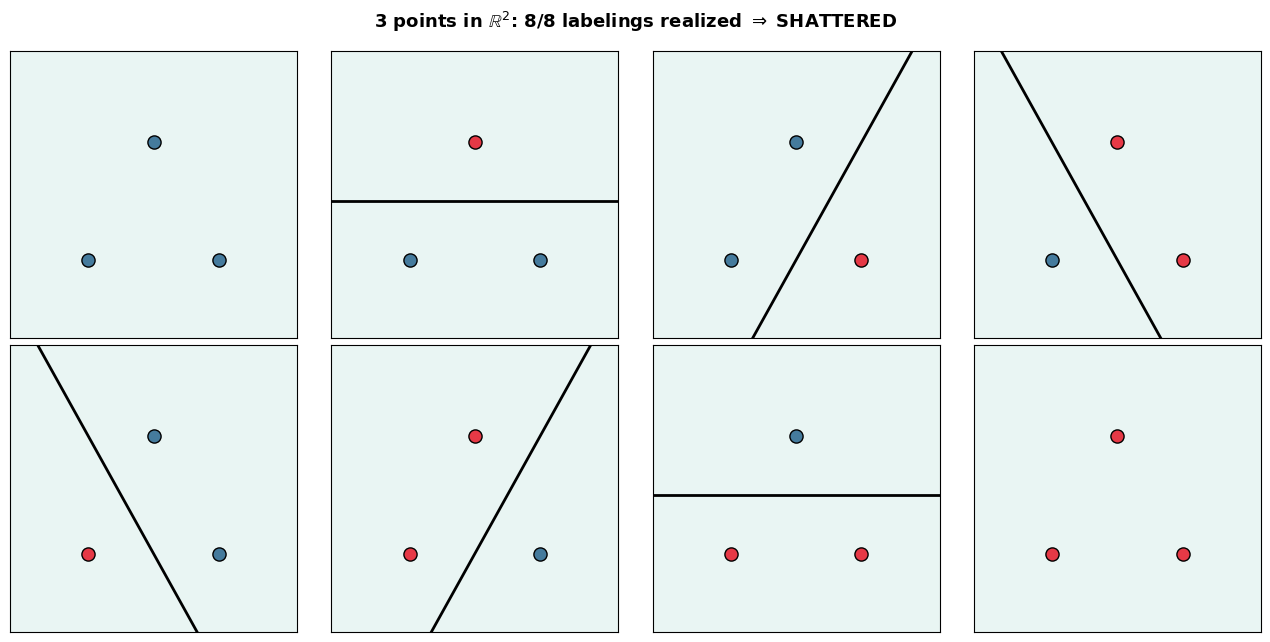

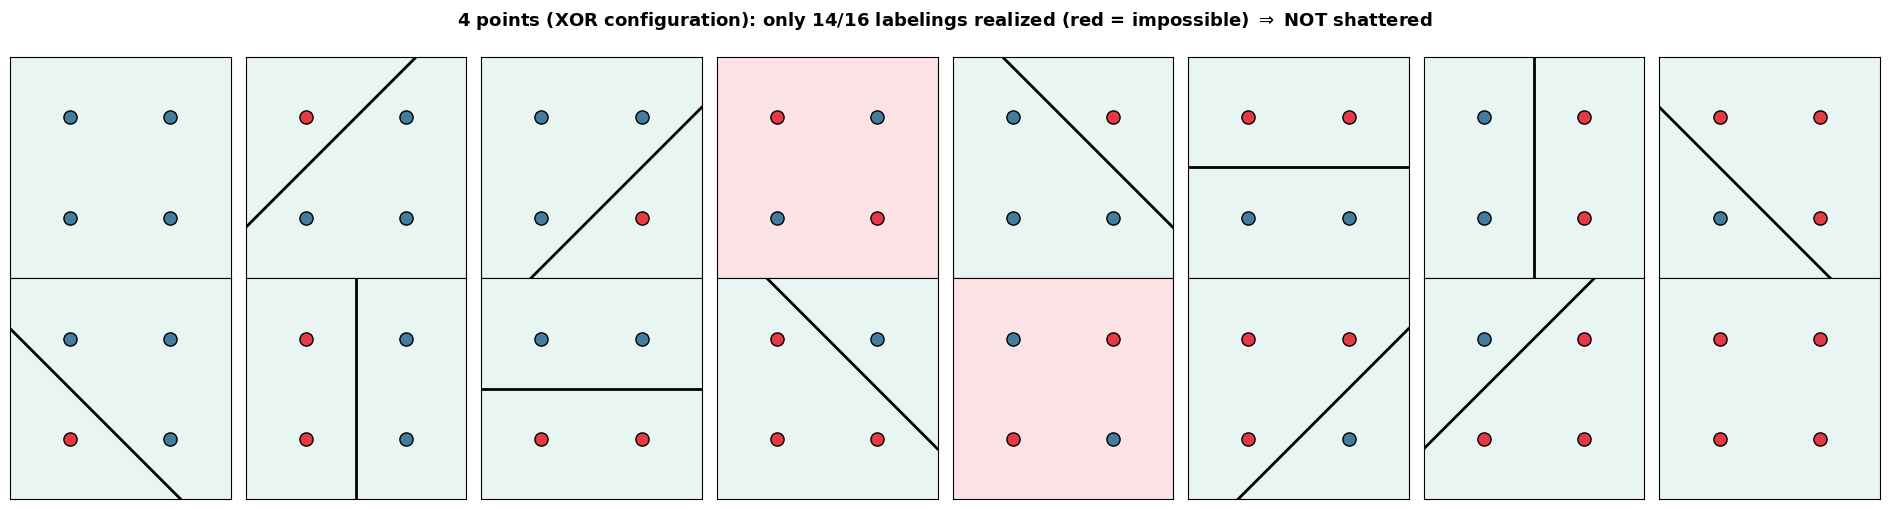

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import minimize, linprog

def separable(X, y):
    # Feasibility LP: exists (w,b) with y_i (w^T x_i + b) >= 1 ?
    N, d = X.shape
    A_ub = -y[:, None] * np.hstack([X, np.ones((N, 1))])
    res = linprog(np.zeros(d + 1), A_ub=A_ub, b_ub=-np.ones(N), bounds=[(None, None)] * (d + 1), method='highs')
    return res.status == 0

def svm_primal_hard(X, y):
    N, d = X.shape
    A = y[:, None] * np.hstack([X, np.ones((N, 1))])
    res = minimize(lambda v: 0.5 * v[:d] @ v[:d], np.zeros(d + 1), jac=lambda v: np.concatenate([v[:d], [0.0]]),
                   constraints=[{'type': 'ineq', 'fun': lambda v: A @ v - 1, 'jac': lambda v: A}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 500})
    return res.x[:d], res.x[d]

def draw(ax, X, y, ok):
    ax.scatter(X[y > 0, 0], X[y > 0, 1], color='#E63946', s=90, edgecolor='k', zorder=5)
    ax.scatter(X[y < 0, 0], X[y < 0, 1], color='#457B9D', s=90, edgecolor='k', zorder=5)
    if ok and len(np.unique(y)) == 2:
        w, b = svm_primal_hard(X, y)
        t = np.linspace(-0.6, 1.6, 2)
        if abs(w[1]) > 1e-9: ax.plot(t, (-b - w[0]*t)/w[1], 'k', lw=2)
        else:                ax.axvline(-b/w[0], color='k', lw=2)
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(-0.6, 1.6); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor('#e9f5f3' if ok else '#fbe3e5')

X3 = np.array([[0.0, 0.0], [1.0, 0.0], [0.5, 0.9]])
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
count3 = 0
for ax, lab in zip(axes.ravel(), product([-1, 1], repeat=3)):
    y = np.array(lab, float); ok = separable(X3, y); count3 += ok
    draw(ax, X3, y, ok)
plt.suptitle(f'3 points in $\\mathbb{{R}}^2$: {count3}/8 labelings realized $\\Rightarrow$ SHATTERED', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

X4 = np.array([[0.0, 0.0], [1.0, 1.0], [1.0, 0.0], [0.0, 1.0]])     # XOR configuration
fig, axes = plt.subplots(2, 8, figsize=(19, 5.2))
count4 = 0
for ax, lab in zip(axes.ravel(), product([-1, 1], repeat=4)):
    y = np.array(lab, float); ok = separable(X4, y); count4 += ok
    draw(ax, X4, y, ok)
plt.suptitle(f'4 points (XOR configuration): only {count4}/16 labelings realized (red = impossible) $\\Rightarrow$ NOT shattered', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 13. The Margin Bound: Capacity Without Dimension

Section 12 says that the VC dimension of hyperplanes grows with $d$. If that were the whole story, the SVM would be hopeless in the high- (or infinite-) dimensional feature spaces of Part V: the PAC bounds of `02` would need $N\gtrsim d$ samples.

**The SVM does not use *all* hyperplanes.** It only accepts those that separate the data **with margin at least $\gamma$**. Restricting to such *$\gamma$-margin hyperplanes* shrinks the class — and with it the VC dimension.

### Shattering With Margin

Say that a set $C$ is **$\gamma$-shattered** if every labeling of $C$ is realized by a hyperplane with geometric margin $\ge\gamma$ on $C$. A margin requirement makes shattering harder: points that are close together can still be split by *some* line, but not by a line that stays $\gamma$ away from both of them.

### Vapnik's Margin Bound [7]

If the data lie in a ball of radius $R$ and only hyperplanes with margin $\ge\gamma$ are allowed:

$$\boxed{\operatorname{VCdim}\le\min\left(\left\lceil\frac{R^2}{\gamma^2}\right\rceil,\ d\right)+1}$$

* For $\gamma\to0$ we recover the usual $d+1$.
* For large $\gamma/R$ the bound **does not depend on $d$ at all**. This is what lets an SVM generalize in a huge feature space: what controls capacity is the ratio $R/\gamma$, and the SVM maximizes $\gamma$ explicitly — it is **structural risk minimization** (`01`) built into the objective.
* Same message in Shalev-Shwartz & Ben-David [5], Ch. 15: the sample complexity of hard-SVM scales like $(R/\gamma)^2/\epsilon$, with no dependence on $d$.

> **Related remark — a support-vector bound.** By Section 9, removing a non-support vector leaves the SVM unchanged, so it is still classified correctly in leave-one-out. Only support vectors can contribute leave-one-out errors: $\ \text{LOO error}\le\dfrac{\#\text{SV}}{N}$. Few support vectors $\Rightarrow$ guaranteed good generalization — another face of the same sparsity.

### Experiment in $\mathbb{R}^2$ ($R=1$)

For points in the unit disk, how large can the margin be while still shattering $n$ points?
* $n=2$: the best is two antipodal points; the max-margin separator for $\{+,-\}$ has $\gamma=1$.
* $n=3$: for the labeling "one vertex vs. the other two", the max margin is half the distance from the vertex to the opposite side. For the **equilateral triangle** inscribed in the circle it equals $3R/4$, and a random search over 20000 configurations never does better.
* $n=4$: never shattered, whatever $\gamma$ (Section 12).

So the empirical VC dimension of $\gamma$-margin lines in the unit disk drops from $3$ to $2$ to $1$ as $\gamma$ grows — compared below with the bound.

Equilateral triangle (R=1): max-margin over the 6 non-trivial labelings = [0.75 0.75 0.75 0.75 0.75 0.75]
  -> gamma-shattered for gamma <= 0.7500   (closed form: 0.7500 = 3R/4)


Random search (20000 configs): best 3-point shattering margin = 0.6683  (never above 3R/4 = 0.75)


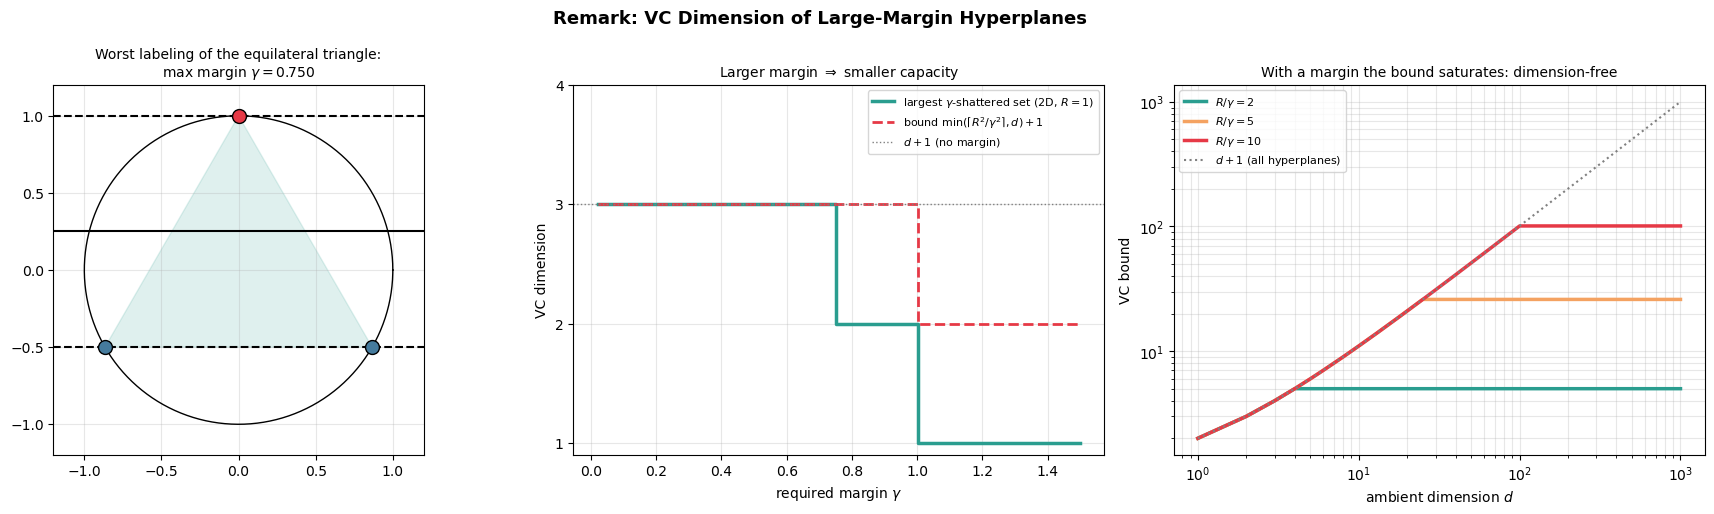

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import minimize

def svm_primal_hard(X, y):
    N, d = X.shape
    A = y[:, None] * np.hstack([X, np.ones((N, 1))])
    res = minimize(lambda v: 0.5 * v[:d] @ v[:d], np.zeros(d + 1), jac=lambda v: np.concatenate([v[:d], [0.0]]),
                   constraints=[{'type': 'ineq', 'fun': lambda v: A @ v - 1, 'jac': lambda v: A}],
                   method='SLSQP', options={'ftol': 1e-12, 'maxiter': 500})
    return res.x[:d], res.x[d]

def point_segment_dist(p, a, b):
    t = np.clip((p - a) @ (b - a) / ((b - a) @ (b - a)), 0, 1)
    return np.linalg.norm(p - (a + t*(b - a)))

def shattering_margin_3(P):
    # Largest gamma at which 3 points are gamma-shattered: the worst labeling is "one vs two",
    # whose max margin is half the distance from the single point to the opposite segment.
    return min(point_segment_dist(P[i], *np.delete(P, i, axis=0)) for i in range(3)) / 2

# (a) Equilateral triangle inscribed in the unit circle: check with the SVM solver
ang = np.deg2rad([90, 210, 330])
T = np.column_stack([np.cos(ang), np.sin(ang)])
margins = []
for lab in product([-1, 1], repeat=3):
    y = np.array(lab, float)
    if len(np.unique(y)) == 1: continue                 # constant labeling: margin unbounded
    w, b = svm_primal_hard(T, y)
    margins.append(1 / np.linalg.norm(w))
print(f"Equilateral triangle (R=1): max-margin over the 6 non-trivial labelings = {np.round(sorted(margins), 4)}")
print(f"  -> gamma-shattered for gamma <= {min(margins):.4f}   (closed form: {shattering_margin_3(T):.4f} = 3R/4)")

# (b) Random search over 3-point configurations inside the unit disk
rng = np.random.default_rng(0)
best, best_P = 0, None
for _ in range(20000):
    r = np.sqrt(rng.uniform(0, 1, 3)); th = rng.uniform(0, 2*np.pi, 3)
    P = np.column_stack([r*np.cos(th), r*np.sin(th)])
    m = shattering_margin_3(P)
    if m > best: best, best_P = m, P
print(f"Random search (20000 configs): best 3-point shattering margin = {best:.4f}  (never above 3R/4 = 0.75)")

# (c) Empirical VC dim of gamma-margin lines in the unit disk vs. Vapnik's bound
R, d = 1.0, 2
gammas = np.linspace(0.02, 1.5, 400)
vc_emp = np.where(gammas <= 0.75, 3, np.where(gammas <= 1.0, 2, 1))
vc_bound = np.minimum(np.ceil(R**2 / gammas**2), d) + 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
th = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(th), np.sin(th), 'k', lw=1)
ax.fill(*np.vstack([T, T[:1]]).T, color='#2A9D8F', alpha=0.15)
y = np.array([1.0, -1.0, -1.0]); w, b = svm_primal_hard(T, y)
xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
ax.contour(xx, yy, w[0]*xx + w[1]*yy + b, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
ax.scatter(*T[y > 0].T, color='#E63946', s=100, edgecolor='k', zorder=5)
ax.scatter(*T[y < 0].T, color='#457B9D', s=100, edgecolor='k', zorder=5)
ax.set_aspect('equal'); ax.set_title(f'Worst labeling of the equilateral triangle:\nmax margin $\\gamma={1/np.linalg.norm(w):.3f}$', fontsize=10)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.step(gammas, vc_emp, where='post', color='#2A9D8F', lw=2.5, label='largest $\\gamma$-shattered set (2D, $R=1$)')
ax.step(gammas, vc_bound, where='post', color='#E63946', lw=2, linestyle='--', label=r'bound $\min(\lceil R^2/\gamma^2\rceil, d)+1$')
ax.axhline(d + 1, color='gray', lw=1, linestyle=':', label='$d+1$ (no margin)')
ax.set_xlabel(r'required margin $\gamma$'); ax.set_ylabel('VC dimension'); ax.set_yticks([1, 2, 3, 4])
ax.set_title('Larger margin $\\Rightarrow$ smaller capacity', fontsize=10)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]
dims = np.arange(1, 1001)
for rg, col in [(2, '#2A9D8F'), (5, '#F4A261'), (10, '#E63946')]:
    ax.plot(dims, np.minimum(np.ceil(rg**2), dims) + 1, color=col, lw=2.5, label=f'$R/\\gamma={rg}$')
ax.plot(dims, dims + 1, color='gray', lw=1.5, linestyle=':', label='$d+1$ (all hyperplanes)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('ambient dimension $d$'); ax.set_ylabel('VC bound')
ax.set_title('With a margin the bound saturates: dimension-free', fontsize=10)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3, which='both')
plt.suptitle('Remark: VC Dimension of Large-Margin Hyperplanes', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
# Part V — Kernel Methods

---
## 14. Feature Maps: When Linear Is Not Enough

Some problems are not linearly separable in the input space — e.g. one class surrounded by the other. As with the polynomial features of `06`/`07`, map the **input attributes** $\mathbf{x}$ to **features** $\phi(\mathbf{x})$ and run the linear method on $\phi(\mathbf{x})$ (CS229 [1] terminology: $\phi$ is the *feature map*).

For $\mathbf{x}\in\mathbb{R}^2$ take the degree-2 map

$$\phi(\mathbf{x}) = \big(x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2\big)\in\mathbb{R}^3$$

A circle $x_1^2+x_2^2=r^2$ in input space becomes the **plane** $z_1+z_3=r^2$ in feature space: concentric circles become linearly separable.

The catch: for $\mathbf{x}\in\mathbb{R}^d$ and all monomials up to degree $k$, $\dim\phi=\binom{d+k}{k}=\mathcal{O}(d^k)$. With $d=1000$, $k=3$ that is $\approx1.7\times10^8$ features per example.

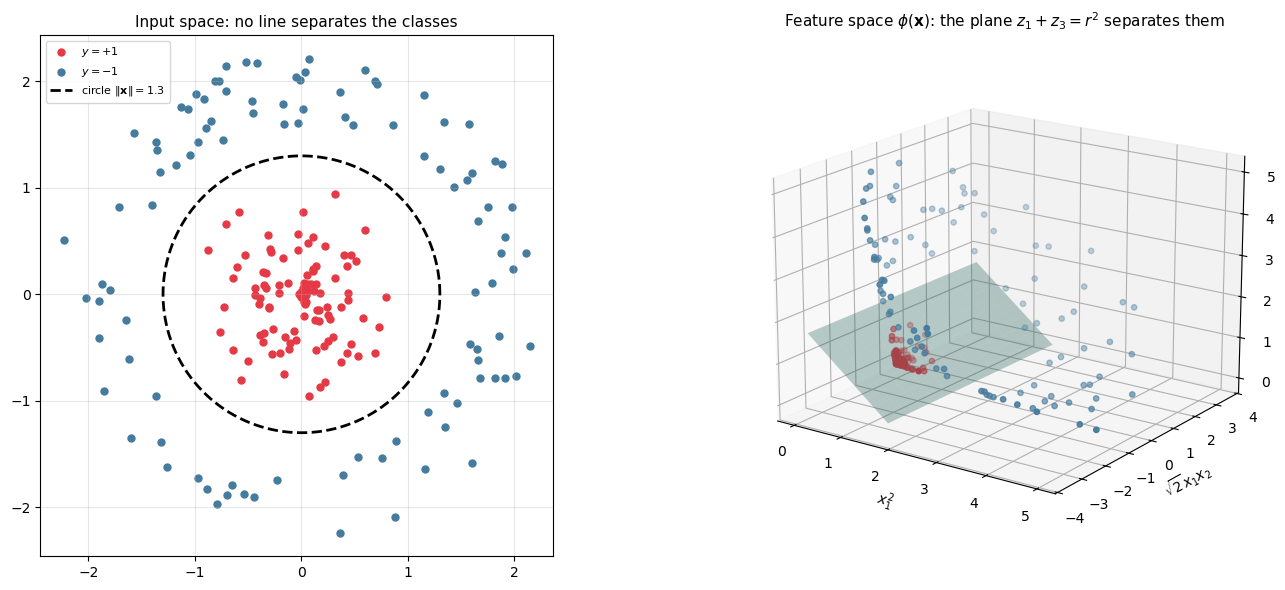

d =     2, degree <= 2:  dim phi = C(d+k, k) = 6
d =    10, degree <= 3:  dim phi = C(d+k, k) = 286
d =   100, degree <= 3:  dim phi = C(d+k, k) = 176,851
d =  1000, degree <= 3:  dim phi = C(d+k, k) = 167,668,501


In [14]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(2)
N = 100
r_in, r_out = np.random.uniform(0, 1.0, N), np.random.uniform(1.6, 2.3, N)
t_in, t_out = np.random.uniform(0, 2*np.pi, N), np.random.uniform(0, 2*np.pi, N)
X_in  = np.column_stack([r_in*np.cos(t_in),  r_in*np.sin(t_in)])
X_out = np.column_stack([r_out*np.cos(t_out), r_out*np.sin(t_out)])

phi = lambda X: np.column_stack([X[:, 0]**2, np.sqrt(2)*X[:, 0]*X[:, 1], X[:, 1]**2])
Z_in, Z_out = phi(X_in), phi(X_out)

fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 2, 1)
ax.scatter(*X_in.T, color='#E63946', s=25, label='$y=+1$')
ax.scatter(*X_out.T, color='#457B9D', s=25, label='$y=-1$')
th = np.linspace(0, 2*np.pi, 300); r0 = 1.3
ax.plot(r0*np.cos(th), r0*np.sin(th), 'k--', lw=2, label=f'circle $\\|\\mathbf{{x}}\\|={r0}$')
ax.set_aspect('equal'); ax.set_title('Input space: no line separates the classes', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = fig.add_subplot(1, 2, 2, projection='3d')
ax.scatter(*Z_in.T, color='#E63946', s=15)
ax.scatter(*Z_out.T, color='#457B9D', s=15)
# plane z1 + z3 = r0^2 (independent of z2)
s, u = np.meshgrid(np.linspace(0, r0**2, 12), np.linspace(-3.5, 3.5, 12))
ax.plot_surface(s, u, r0**2 - s, alpha=0.3, color='#2A9D8F')
ax.set_xlabel('$x_1^2$'); ax.set_ylabel('$\\sqrt{2}x_1x_2$'); ax.set_zlabel('$x_2^2$')
ax.set_title('Feature space $\\phi(\\mathbf{x})$: the plane $z_1+z_3=r^2$ separates them', fontsize=11)
ax.view_init(elev=18, azim=-55)
plt.tight_layout(); plt.show()

from math import comb
for d, k in [(2, 2), (10, 3), (100, 3), (1000, 3)]:
    print(f"d = {d:5d}, degree <= {k}:  dim phi = C(d+k, k) = {comb(d + k, k):,}")

---
## 15. The Kernel Trick

Recall observation 2 of Section 8: the SVM dual and the prediction rule use the data **only through inner products**. After the feature map they become $\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)$. Define the **kernel**

$$\boxed{K(\mathbf{x},\mathbf{z}) = \langle\phi(\mathbf{x}),\phi(\mathbf{z})\rangle}$$

If $K$ can be evaluated **directly**, without forming $\phi$, then $\phi$ is never needed:

$$\text{dual:}\quad \max_{\boldsymbol\alpha}\sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\,K(\mathbf{x}_i,\mathbf{x}_j), \qquad \text{prediction:}\quad f(\mathbf{x})=\sum_{i\in\mathcal{S}}\alpha_iy_i\,K(\mathbf{x}_i,\mathbf{x})+b$$

### Polynomial Kernel

For $K(\mathbf{x},\mathbf{z})=(\mathbf{x}^T\mathbf{z})^2$:

$$(\mathbf{x}^T\mathbf{z})^2=\Big(\sum_ix_iz_i\Big)\Big(\sum_jx_jz_j\Big)=\sum_{i,j}(x_ix_j)(z_iz_j)=\langle\phi(\mathbf{x}),\phi(\mathbf{z})\rangle, \quad \phi(\mathbf{x})=(x_ix_j)_{i,j=1}^d$$

For $d=2$ this is exactly the map of Section 14 (the two cross terms $x_1x_2$, $x_2x_1$ merge into $\sqrt2\,x_1x_2$). More generally

$$K(\mathbf{x},\mathbf{z})=(\mathbf{x}^T\mathbf{z}+c)^k$$

corresponds to all monomials of degree $\le k$, a $\binom{d+k}{k}$-dimensional feature space, yet it costs **$\mathcal{O}(d)$** to evaluate: one inner product plus a scalar power. $c\ge0$ weights lower- vs. higher-order terms.

> **General principle.** *Any* algorithm that can be written in terms of inner products only (SVM, ridge regression, PCA, $k$-NN, perceptron, ...) can be **kernelized** by replacing $\langle\mathbf{x},\mathbf{z}\rangle$ with $K(\mathbf{x},\mathbf{z})$. The Representer Theorem [5] guarantees that for $L_2$-regularized losses the optimum always has the form $\mathbf{w}=\sum_i\beta_i\phi(\mathbf{x}_i)$ — which is what makes this possible.

   d  k    dim phi |  <phi(x),phi(z)>    (x^T z + c)^k |  t explicit   t kernel
   2  2          6 |       0.00189192       0.00189192 |     0.0003s  0.000004s
   5  3         56 |       0.12355285       0.12355285 |     0.0015s  0.000003s
  20  3      1,771 |       2.89212613       2.89212613 |     0.0496s  0.000007s


  50  3     23,426 |      11.04403316      11.04403316 |     0.6369s  0.000009s


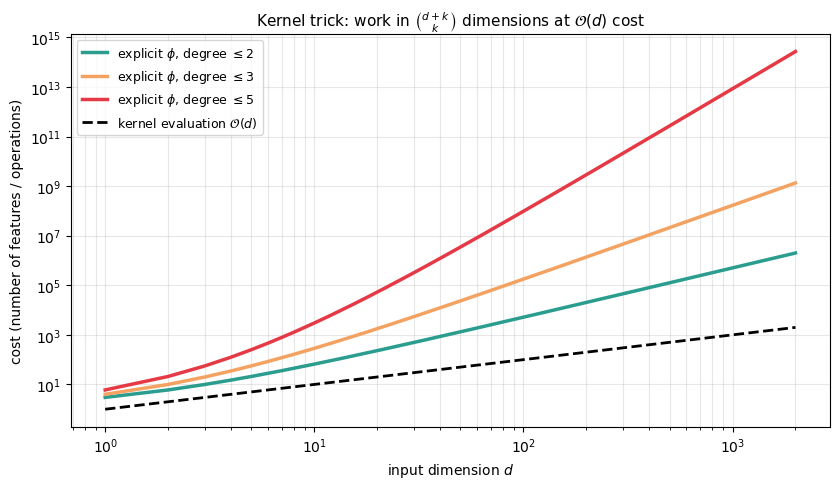

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations_with_replacement
from math import comb, factorial
from collections import Counter
import time

def phi_poly(x, k, c):
    # Explicit feature map of (x^T z + c)^k: all monomials of degree <= k with multinomial weights
    d = len(x); feats = []
    xc = np.append(x, np.sqrt(c))                        # treat sqrt(c) as an extra coordinate
    for combo in combinations_with_replacement(range(d + 1), k):
        cnt = Counter(combo)
        coef = factorial(k) / np.prod([factorial(v) for v in cnt.values()])
        feats.append(np.sqrt(coef) * np.prod([xc[i] for i in combo]))
    return np.array(feats)

rng = np.random.default_rng(1)
print(f"{'d':>4} {'k':>2} {'dim phi':>10} | {'<phi(x),phi(z)>':>16} {'(x^T z + c)^k':>16} | {'t explicit':>11} {'t kernel':>10}")
for d, k in [(2, 2), (5, 3), (20, 3), (50, 3)]:
    x, z, c = rng.normal(size=d), rng.normal(size=d), 1.0
    t0 = time.perf_counter(); px, pz = phi_poly(x, k, c), phi_poly(z, k, c); explicit = px @ pz; t1 = time.perf_counter()
    kernel = (x @ z + c)**k; t2 = time.perf_counter()
    print(f"{d:>4} {k:>2} {len(px):>10,} | {explicit:>16.8f} {kernel:>16.8f} | {t1-t0:>10.4f}s {t2-t1:>9.6f}s")

dims = np.arange(1, 2001)
fig, ax = plt.subplots(figsize=(8.5, 5))
for k, col in [(2, '#2A9D8F'), (3, '#F4A261'), (5, '#E63946')]:
    ax.loglog(dims, [comb(d + k, k) for d in dims], color=col, lw=2.5, label=f'explicit $\\phi$, degree $\\leq {k}$')
ax.loglog(dims, dims, 'k--', lw=2, label=r'kernel evaluation $\mathcal{O}(d)$')
ax.set_xlabel('input dimension $d$'); ax.set_ylabel('cost (number of features / operations)')
ax.set_title('Kernel trick: work in $\\binom{d+k}{k}$ dimensions at $\\mathcal{O}(d)$ cost', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, which='both')
plt.tight_layout(); plt.show()

---
## 16. Valid Kernels: Mercer's Theorem and the Gram Matrix

Given a function $K(\mathbf{x},\mathbf{z})$, when does a feature map $\phi$ with $K=\langle\phi(\cdot),\phi(\cdot)\rangle$ exist?

### Necessary condition

For any points $\{\mathbf{x}_1,\dots,\mathbf{x}_n\}$ build the **Gram (kernel) matrix** $\mathbf{K}_{ij}=K(\mathbf{x}_i,\mathbf{x}_j)$. If $K$ is a valid kernel:
* **Symmetric:** $\mathbf{K}_{ij}=\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)=\mathbf{K}_{ji}$.
* **Positive semi-definite:** for any $\mathbf{v}\in\mathbb{R}^n$,
$$\mathbf{v}^T\mathbf{K}\mathbf{v}=\sum_{i,j}v_iv_j\,\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j)=\Big\|\sum_iv_i\phi(\mathbf{x}_i)\Big\|^2\ge0$$

### Mercer's Theorem (sufficiency)

$K$ is a valid (Mercer) kernel **if and only if**, for every finite set of points, the Gram matrix is **symmetric PSD** — i.e. **all its eigenvalues are $\ge0$**.

> **This is where eigenvalues genuinely enter the SVM story.** The multipliers $\alpha_i$ are *not* eigenvalues; but checking a kernel means checking the spectrum of $\mathbf{K}$ — exactly the eigendecomposition of `03`/`04`. PSD $\mathbf{K}$ also makes $\mathbf{Q}=(\mathbf{y}\mathbf{y}^T)\odot\mathbf{K}$ PSD, so the dual stays a **convex** QP with a global optimum.

### Building New Kernels

If $K_1,K_2$ are valid, so are: $\ cK_1\ (c>0)$, $\ K_1+K_2$, $\ K_1K_2$, $\ f(\mathbf{x})K_1(\mathbf{x},\mathbf{z})f(\mathbf{z})$, $\ \exp(K_1)$, and $p(K_1)$ for any polynomial $p$ with non-negative coefficients. These rules prove validity of the polynomial and Gaussian kernels without exhibiting $\phi$.

Below, the spectrum of $\mathbf{K}$ for several candidate functions on the same random points:

candidate                        symmetric  min eigenvalue  valid?
linear  x^T z                         True      -8.532e-15  PSD -> valid
polynomial  (x^T z + 1)^3             True      -1.206e-13  PSD -> valid
Gaussian  exp(-||x-z||^2 / 2)         True       1.822e-05  PSD -> valid
-||x-z||^2                            True      -3.074e+02  NOT PSD
sigmoid  tanh(x^T z - 1)              True      -3.042e+01  NOT PSD


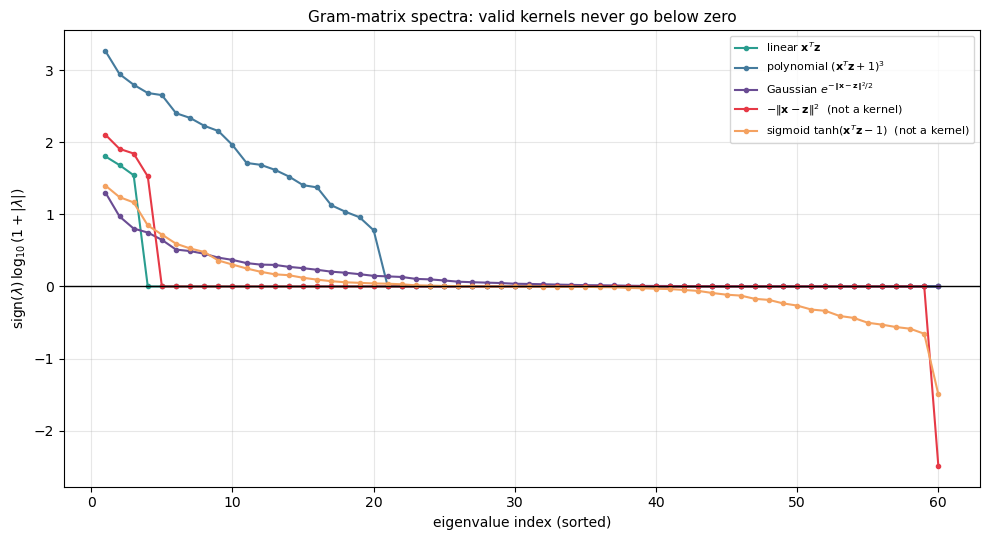

In [16]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
X = rng.normal(size=(60, 3))
sq = np.sum(X**2, axis=1)
D2 = sq[:, None] + sq[None, :] - 2 * X @ X.T          # squared pairwise distances

candidates = {   # plot label -> (Gram matrix, printable name)
    r'linear $\mathbf{x}^T\mathbf{z}$':                 (X @ X.T, 'linear  x^T z'),
    r'polynomial $(\mathbf{x}^T\mathbf{z}+1)^3$':       ((X @ X.T + 1)**3, 'polynomial  (x^T z + 1)^3'),
    r'Gaussian $e^{-\|\mathbf{x}-\mathbf{z}\|^2/2}$':   (np.exp(-D2 / 2), 'Gaussian  exp(-||x-z||^2 / 2)'),
    r'$-\|\mathbf{x}-\mathbf{z}\|^2$  (not a kernel)':  (-D2, '-||x-z||^2'),
    r'sigmoid $\tanh(\mathbf{x}^T\mathbf{z}-1)$  (not a kernel)': (np.tanh(X @ X.T - 1), 'sigmoid  tanh(x^T z - 1)'),
}

fig, ax = plt.subplots(figsize=(10, 5.5))
cols = ['#2A9D8F', '#457B9D', '#6a4c93', '#E63946', '#F4A261']
print(f"{'candidate':32s} {'symmetric':>9} {'min eigenvalue':>15}  valid?")
for (name, (K, plain)), col in zip(candidates.items(), cols):
    ev = np.linalg.eigvalsh(K)[::-1]
    sym = np.allclose(K, K.T)
    valid = sym and ev.min() > -1e-8 * abs(ev).max()
    print(f"{plain:32s} {str(sym):>9} {ev.min():>15.3e}  {'PSD -> valid' if valid else 'NOT PSD'}")
    ax.plot(np.arange(1, len(ev) + 1), np.sign(ev) * np.log10(1 + np.abs(ev)), 'o-', ms=3, lw=1.5, color=col, label=name)
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('eigenvalue index (sorted)'); ax.set_ylabel(r'$\mathrm{sign}(\lambda)\,\log_{10}(1+|\lambda|)$')
ax.set_title('Gram-matrix spectra: valid kernels never go below zero', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 17. The Gaussian (RBF) Kernel: An Infinite-Dimensional Feature Map

$$\boxed{K(\mathbf{x},\mathbf{z})=\exp\!\left(-\frac{\|\mathbf{x}-\mathbf{z}\|^2}{2\sigma^2}\right)}$$

$K\approx1$ for nearby points and $K\to0$ for distant ones: it is a **similarity** with length scale $\sigma$ (often written with $\gamma_{\text{RBF}}=1/2\sigma^2$, not to be confused with the margin).

### Which $\phi$? (1D)

Expanding $\|x-z\|^2=x^2+z^2-2xz$ and Taylor-expanding $e^{xz/\sigma^2}$:

$$K(x,z)=e^{-x^2/2\sigma^2}e^{-z^2/2\sigma^2}\sum_{n=0}^\infty\frac{(xz/\sigma^2)^n}{n!}=\sum_{n=0}^\infty\phi_n(x)\,\phi_n(z), \qquad \phi_n(x)=e^{-x^2/2\sigma^2}\frac{x^n}{\sigma^n\sqrt{n!}}$$

The feature map has **infinitely many** coordinates (monomials of every degree): no computer could store $\phi(x)$, but $K(x,z)$ costs $\mathcal{O}(d)$.

### Capacity

With the RBF kernel, $N$ distinct points always have a full-rank Gram matrix, so **any** labeling is separable in feature space: the VC dimension of the induced hyperplanes is **infinite**. Generalization must come from the **margin** (Section 13) and from $C$ and $\sigma$, chosen by validation.

| $\sigma$ | Behavior |
|---|---|
| small | each point influences only its immediate neighborhood $\Rightarrow$ wiggly boundary, many SVs, overfitting |
| large | $K$ nearly constant over the data $\Rightarrow$ almost linear boundary, underfitting |

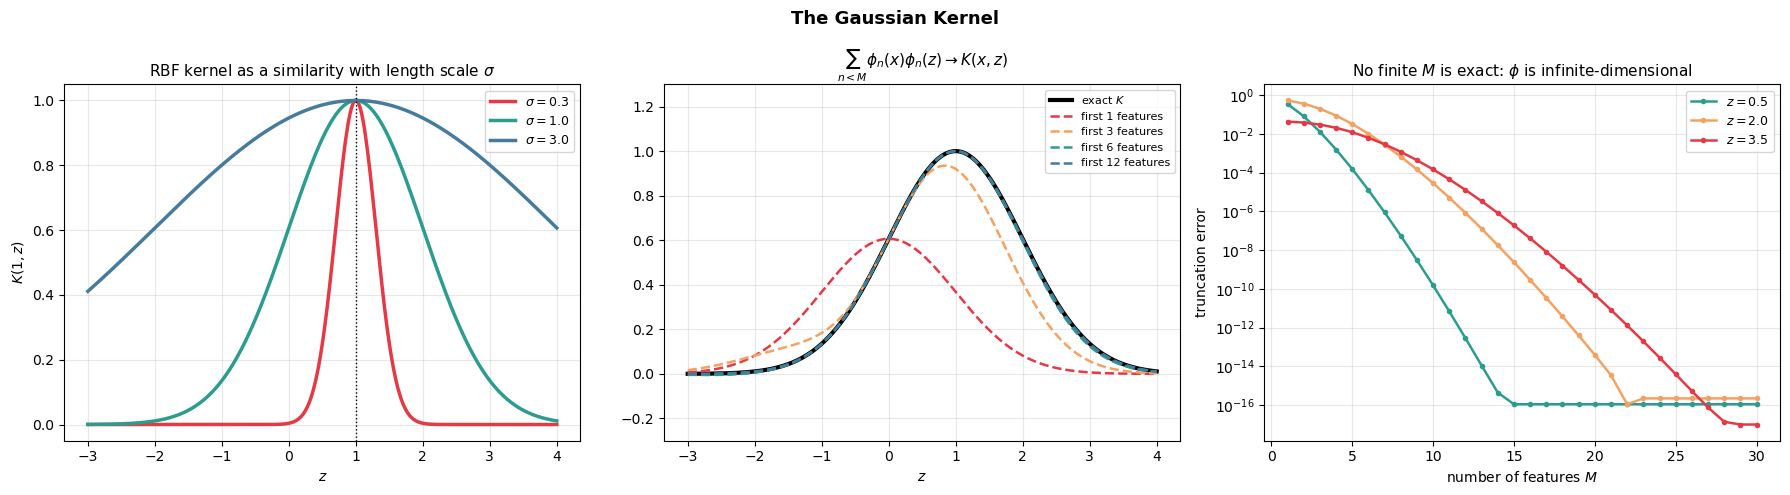

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial, sqrt

sigma = 1.0
K_true = lambda x, z: np.exp(-(x - z)**2 / (2*sigma**2))
phi_n  = lambda x, n: np.exp(-x**2 / (2*sigma**2)) * x**n / (sigma**n * sqrt(factorial(n)))

x0 = 1.0
z  = np.linspace(-3, 4, 400)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
for s, col in [(0.3, '#E63946'), (1.0, '#2A9D8F'), (3.0, '#457B9D')]:
    ax.plot(z, np.exp(-(x0 - z)**2 / (2*s**2)), color=col, lw=2.5, label=f'$\\sigma={s}$')
ax.axvline(x0, color='k', lw=1, linestyle=':')
ax.set_xlabel('$z$'); ax.set_ylabel(f'$K({x0:g}, z)$'); ax.set_title(r'RBF kernel as a similarity with length scale $\sigma$', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(z, K_true(x0, z), 'k', lw=3, label='exact $K$')
for M, col in [(1, '#E63946'), (3, '#F4A261'), (6, '#2A9D8F'), (12, '#457B9D')]:
    approx = sum(phi_n(x0, n) * phi_n(z, n) for n in range(M))
    ax.plot(z, approx, color=col, lw=1.8, linestyle='--', label=f'first {M} features')
ax.set_ylim(-0.3, 1.3); ax.set_xlabel('$z$'); ax.set_title(r'$\sum_{n<M}\phi_n(x)\phi_n(z)\to K(x,z)$', fontsize=11)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]
Ms = np.arange(1, 31)
for zz, col in [(0.5, '#2A9D8F'), (2.0, '#F4A261'), (3.5, '#E63946')]:
    err = [abs(K_true(x0, zz) - sum(phi_n(x0, n) * phi_n(zz, n) for n in range(M))) for M in Ms]
    ax.semilogy(Ms, np.maximum(err, 1e-17), 'o-', ms=3, color=col, lw=1.8, label=f'$z={zz}$')
ax.set_xlabel('number of features $M$'); ax.set_ylabel('truncation error')
ax.set_title('No finite $M$ is exact: $\\phi$ is infinite-dimensional', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, which='both')
plt.suptitle('The Gaussian Kernel', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 18. Kernel SVM End-to-End

Putting everything together. The soft-margin dual of Section 10 with $\mathbf{x}_i^T\mathbf{x}_j$ replaced by $K(\mathbf{x}_i,\mathbf{x}_j)$:

1. Build the Gram matrix $\mathbf{K}$ ($N\times N$).
2. Solve $\ \min_{\boldsymbol\alpha}\tfrac12\boldsymbol\alpha^T\big[(\mathbf{y}\mathbf{y}^T)\odot\mathbf{K}\big]\boldsymbol\alpha-\mathbf{1}^T\boldsymbol\alpha\ $ s.t. $0\le\alpha_i\le C$, $\boldsymbol\alpha^T\mathbf{y}=0$.
3. Support vectors $\mathcal{S}=\{i:\alpha_i>0\}$ (Section 9); $b$ from the free ones ($0<\alpha_s<C$):
   $$b=\frac{1}{|\mathcal{S}_{\text{free}}|}\sum_{s\in\mathcal{S}_{\text{free}}}\Big(y_s-\sum_{i\in\mathcal{S}}\alpha_iy_iK(\mathbf{x}_i,\mathbf{x}_s)\Big)$$
4. Predict with $\ \hat y(\mathbf{x})=\operatorname{sign}\Big(\sum_{i\in\mathcal{S}}\alpha_iy_iK(\mathbf{x}_i,\mathbf{x})+b\Big)$.

$\mathbf{w}$ is **never** formed — it lives in the feature space. Only $\boldsymbol\alpha$ and the support vectors are stored.

Dataset: two interleaving half-moons, not linearly separable.

model                      C  #SV  free  bound  train acc  test acc
Linear                   1.0   54     2     52      0.838     0.857


Polynomial k=3           1.0   32     6     26      0.994     0.990


RBF sigma=0.1           10.0  120   120      0      1.000     0.987


RBF sigma=0.5           10.0   16    10      6      0.994     0.990


RBF sigma=3             10.0   54     3     51      0.844     0.870


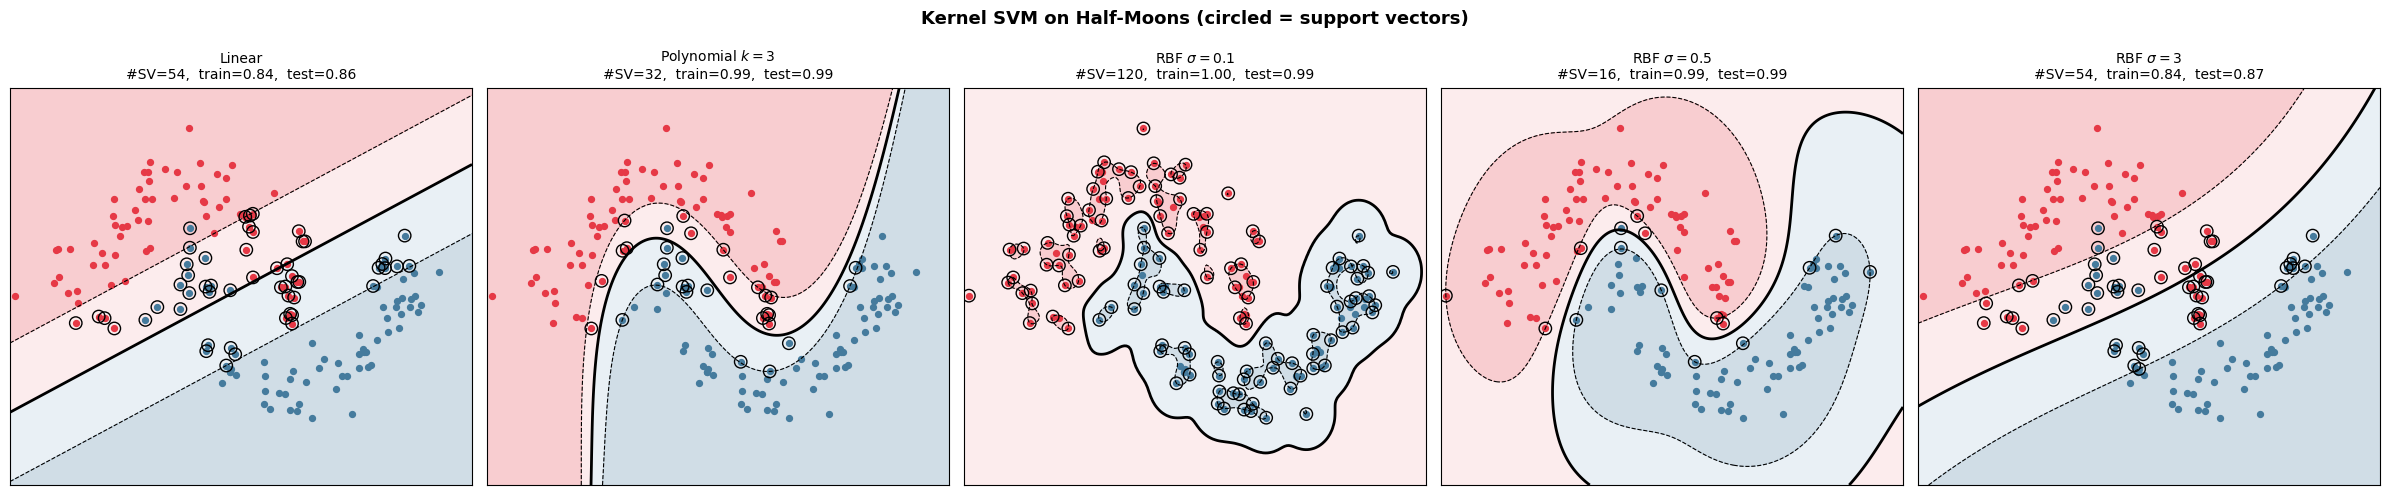

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def make_moons(n, noise, seed):
    rng = np.random.default_rng(seed)
    t1, t2 = rng.uniform(0, np.pi, n), rng.uniform(0, np.pi, n)
    A = np.column_stack([np.cos(t1), np.sin(t1)])
    B = np.column_stack([1 - np.cos(t2), 0.5 - np.sin(t2)])
    X = np.vstack([A, B]) + rng.normal(0, noise, (2*n, 2))
    return X, np.concatenate([np.ones(n), -np.ones(n)])

def rbf_kernel(A, B, sigma):
    d2 = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T
    return np.exp(-np.maximum(d2, 0) / (2 * sigma**2))

def poly_kernel(A, B, k=3, c=1.0):
    return (A @ B.T + c)**k

def linear_kernel(A, B):
    return A @ B.T

class KernelSVM:
    def __init__(self, kernel, C=1.0, tol=1e-5):
        self.kernel, self.C, self.tol = kernel, C, tol

    def fit(self, X, y):
        N = len(y)
        K = self.kernel(X, X)                                           # step 1
        Q = np.outer(y, y) * K
        res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(N), jac=lambda a: Q @ a - 1,
                       bounds=[(0, self.C)] * N,
                       constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                       method='SLSQP', options={'ftol': 1e-10, 'maxiter': 2000})   # step 2
        a = res.x
        sv   = a > self.tol * self.C                                    # step 3
        free = sv & (a < self.C * (1 - self.tol))
        ref  = free if free.any() else sv
        self.X_sv, self.y_sv, self.a_sv = X[sv], y[sv], a[sv]
        self.b = np.mean(y[ref] - (a[sv] * y[sv]) @ K[np.ix_(sv, ref)])
        self.n_free, self.n_bound = free.sum(), (sv & ~free).sum()
        return self

    def decision_function(self, X):                                     # step 4: only SVs needed
        return (self.a_sv * self.y_sv) @ self.kernel(self.X_sv, X) + self.b

    def predict(self, X):
        return np.sign(self.decision_function(X))

X, y = make_moons(80, 0.15, seed=0)
X_test, y_test = make_moons(300, 0.15, seed=1)

configs = [
    ('Linear',                 linear_kernel,                       1.0),
    ('Polynomial $k=3$',       lambda A, B: poly_kernel(A, B, 3),   1.0),
    ('RBF $\\sigma=0.1$',      lambda A, B: rbf_kernel(A, B, 0.1),  10.0),
    ('RBF $\\sigma=0.5$',      lambda A, B: rbf_kernel(A, B, 0.5),  10.0),
    ('RBF $\\sigma=3$',        lambda A, B: rbf_kernel(A, B, 3.0),  10.0),
]

xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 220), np.linspace(-1.2, 1.7, 220))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(1, 5, figsize=(24, 5))
print(f"{'model':22s} {'C':>5} {'#SV':>4} {'free':>5} {'bound':>6} {'train acc':>10} {'test acc':>9}")
for ax, (name, kern, C) in zip(axes, configs):
    m = KernelSVM(kern, C=C).fit(X, y)
    F = m.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, F, levels=[-1e9, -1, 0, 1, 1e9], colors=['#457B9D', '#a8c5da', '#f4b6bb', '#E63946'], alpha=0.25)
    ax.contour(xx, yy, F, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=[0.8, 2, 0.8])
    ax.scatter(X[y > 0, 0], X[y > 0, 1], color='#E63946', s=18)
    ax.scatter(X[y < 0, 0], X[y < 0, 1], color='#457B9D', s=18)
    ax.scatter(m.X_sv[:, 0], m.X_sv[:, 1], s=80, facecolor='none', edgecolor='k', lw=1)
    tr, te = np.mean(m.predict(X) == y), np.mean(m.predict(X_test) == y_test)
    ax.set_title(f'{name}\n#SV={len(m.a_sv)},  train={tr:.2f},  test={te:.2f}', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    print(f"{name.replace('$', '').replace(chr(92), ''):22s} {C:>5} {len(m.a_sv):>4} {m.n_free:>5} {m.n_bound:>6} {tr:>10.3f} {te:>9.3f}")
plt.suptitle('Kernel SVM on Half-Moons (circled = support vectors)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## Summary

| Concept | Key Formula | Core Insight |
|---------|-------------|---------------|
| Lagrangian | $\mathcal{L}=f+\sum_i\alpha_ig_i+\sum_j\beta_jh_j,\ \alpha_i\ge0$ | Constrained problem $\to$ unconstrained min–max |
| Weak / strong duality | $d^\star\le p^\star$; $=$ if convex + Slater | Solve the dual instead of the primal |
| KKT | stationarity, primal & dual feasibility, $\alpha_ig_i=0$ | Necessary & sufficient for convex problems; optimality certificate |
| Geometric margin | $\gamma=\min_i y_i(\mathbf{w}^T\mathbf{x}_i+b)/\|\mathbf{w}\|$ | Scale-invariant; fix $\hat\gamma=1\Rightarrow\gamma=1/\|\mathbf{w}\|$ |
| Hard-margin primal | $\min\frac12\|\mathbf{w}\|^2$ s.t. $y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1$ | Convex QP, unique solution |
| Dual | $\max\sum\alpha_i-\frac12\sum\alpha_i\alpha_jy_iy_j\mathbf{x}_i^T\mathbf{x}_j$, $\sum\alpha_iy_i=0$ | Data enter only via inner products |
| Support vectors | $\alpha_i>0\Rightarrow y_if(\mathbf{x}_i)=1$; $\mathbf{w}=\sum_{i\in\mathcal{S}}\alpha_iy_i\mathbf{x}_i$ | Complementary slackness $\Rightarrow$ sparse solution |
| Soft margin | $0\le\alpha_i\le C$; $\xi_i=\max(0,1-y_if(\mathbf{x}_i))$ | Box constraint; hinge loss $=$ regularized ERM |
| VC of hyperplanes | $d+1$ | 3 points shattered in $\mathbb{R}^2$, 4 never |
| Margin bound | $\operatorname{VCdim}\le\min(\lceil R^2/\gamma^2\rceil,d)+1$ | Large margin $\Rightarrow$ dimension-free capacity |
| Kernel trick | $K(\mathbf{x},\mathbf{z})=\langle\phi(\mathbf{x}),\phi(\mathbf{z})\rangle$ | Linear in $\phi$-space at $\mathcal{O}(d)$ cost |
| Mercer | Gram matrix symmetric PSD $\iff$ valid kernel | Check the eigenvalues of $\mathbf{K}$ |
| RBF kernel | $e^{-\|\mathbf{x}-\mathbf{z}\|^2/2\sigma^2}$ | Infinite-dimensional $\phi$; capacity controlled by margin, $C$, $\sigma$ |